# calc_03a. ERA5: the moment test (calculations)

Two questions, asked of ERA5 and the LESFMIP ensembles over the years they share (1979–2013):

1. **Is each model consistent with ERA5?** Could ERA5 be one more member of a model's historical ensemble? (Part 1: this notebook, the moment test and the other statistics, and notebook calc_03b, the rank histograms)
2. **Is the observed change detectable, and which forcings is it consistent with?** (Part 2, notebook calc_03c)

This notebook works out the climatologies, then eight statistics of every historical member and of ERA5: the four moments (mean, standard deviation, skewness, excess kurtosis), the trend, the width (Q95 − Q05) and the lower and upper tails. Each one is worked out on an example first, then for every model at every grid point, and saved as it is: every member's value and ERA5's, in `RESULTS_DIR` (`results/tas/sample` or `results/tas/full` under `SCRATCH_DIR`). Nothing is ranked here. Where ERA5 falls among the members (its percentile, the verdicts and the field test) is worked out from the saved values where they are used: notebooks plot_01a to plot_01c and plot_06, and calc_03b's table of every test. Run this notebook before calc_03b.

## Setup

In [2]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from extant import datatree, era5_evaluation as ev, observed_change as oc, preprocessing as pp
from extant.config import MAIN_EXPERIMENTS, SATELLITE_YEAR_RANGE, VARIABLES
from extant.datatree import skip_empty
from extant.logger import setup_logging
from extant.plots import charts, forced_response as fr, methods
from extant.stats import nan_quantile
from plotting_modules.constants import FORCING_COLORS, SEASONS

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [3]:
%matplotlib inline

## Settings

The experiments (`MAIN_EXPERIMENTS`) and the years ERA5 and LESFMIP share (`SATELLITE_YEAR_RANGE`) are in `extant/config.py`, and the order of the seasons (`SEASONS`) in `plotting_modules/constants.py`, the same for every notebook. Only this notebook's own choices are here.

In [4]:
#(t): The variable: its name and its units once notebook calc_01 has converted it (VARIABLE.name, VARIABLE.units)
VARIABLE = VARIABLES['tas']

In [5]:
#(t): The grid point of the tests at one point (the 2.5° cell nearest config.POINT, on the Antarctic plateau)
SAMPLE_LAT_LON = dict(lat=-82.5, lon=120.0)

#(t): The model of the one-model quick looks
EXAMPLE_MODEL = 'CanESM5'

In [6]:
#(t): Where notebook calc_01's seasonal means are, and where this notebook's results go: JASMIN's scratch
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SCRATCH_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt')

## Open the Data

Run **one** of the next two sections. Both leave `lesfmip_season_tree` (seasonal means, /<model>/<experiment>, on member × year × season × lat × lon), `era5_seasonal_da` (ERA5 on year × season × lat × lon, on the same grid), all in °C, and `RESULTS_DIR`, where the results are saved.

### Sample data

The 3×3 block of grid cells around the point in `tests/data` (two models), put through notebook calc_01's pre-processing.

In [7]:
#(t): The sample's files, in this repository: <model>_<experiment>_sample.nc, monthly tas in K on (member, time, lat, lon)
SAMPLE_DIR = Path('../tests/data')
sample_files = sorted(SAMPLE_DIR.glob('*_*_sample.nc'))
sample_files

[PosixPath('../tests/data/CanESM5_hist-GHG_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-aer_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-lu_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-nat_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-sol_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-volc_sample.nc'),
 PosixPath('../tests/data/CanESM5_historical_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-GHG_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-aer_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-lu_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-nat_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-sol_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-volc_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_historical_sample.nc')]

In [187]:
#(t): The model and experiment of each file, from its name
sample_names = [path.stem.removesuffix('_sample').rsplit('_', 1) for path in sample_files]

In [188]:
#(t): Each file of the experiments analysed opened, as a DataTree /<model>/<experiment>
lesfmip_monthly_tree = xr.DataTree.from_dict({f'{model}/{experiment}': xr.open_dataset(path).load()
                                              for path, (model, experiment) in zip(sample_files, sample_names)
                                              if experiment in MAIN_EXPERIMENTS})

In [189]:
#(t): Seasonal means in °C, through notebook calc_01's pre-processing (pp.seasonal_tree: to °C, cut at 2014-12, complete
#(t): seasons in whole years)
lesfmip_season_tree = pp.seasonal_tree(lesfmip_monthly_tree, VARIABLE.name).compute()

In [190]:
#(t): ERA5's sample file: monthly tas in K from 1979, on (time, lat, lon)
era5_sample_path = SAMPLE_DIR / 'era5_sample.nc'
era5_monthly_da = xr.open_dataarray(era5_sample_path).load()
era5_sample_path

PosixPath('../tests/data/era5_sample.nc')

In [191]:
#(t): Its seasonal means in °C, on the models' grid (pp.seasonal_era5, as in notebook calc_01)
era5_seasonal_da = pp.seasonal_era5(era5_monthly_da, VARIABLE.name, like=lesfmip_season_tree)

In [192]:
#(t): Where the sample's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

The seasonal means notebook calc_01 saved (section 3) in `SCRATCH_DIR`. Opening is lazy.

In [8]:
#(t): The two stores notebook calc_01 saved
seasonal_path = SCRATCH_DIR / 'seasonal' / f'lesfmip_{VARIABLE.name}.zarr'
era5_path = SCRATCH_DIR / 'seasonal' / f'era5_{VARIABLE.name}.zarr'
seasonal_path, era5_path

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr'),
 PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/era5_tas.zarr'))

In [9]:
#(t): Every model and experiment notebook calc_01 saved
lesfmip_saved_tree = xr.open_datatree(seasonal_path, engine='zarr', chunks={})

In [10]:
#(t): Only the experiments analysed (filter keeps the model nodes above them)
lesfmip_season_tree = lesfmip_saved_tree.filter(lambda node: node.name in MAIN_EXPERIMENTS)

In [11]:
#(t): ERA5's seasonal means
era5_seasonal_da = xr.open_zarr(era5_path)[VARIABLE.name].load()

In [12]:
#(t): Where the full data's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

In [34]:
list(lesfmip_season_tree['GISS-E2-1-G'])

['hist-GHG', 'hist-nat', 'historical', 'hist-totalO3', 'hist-aer']

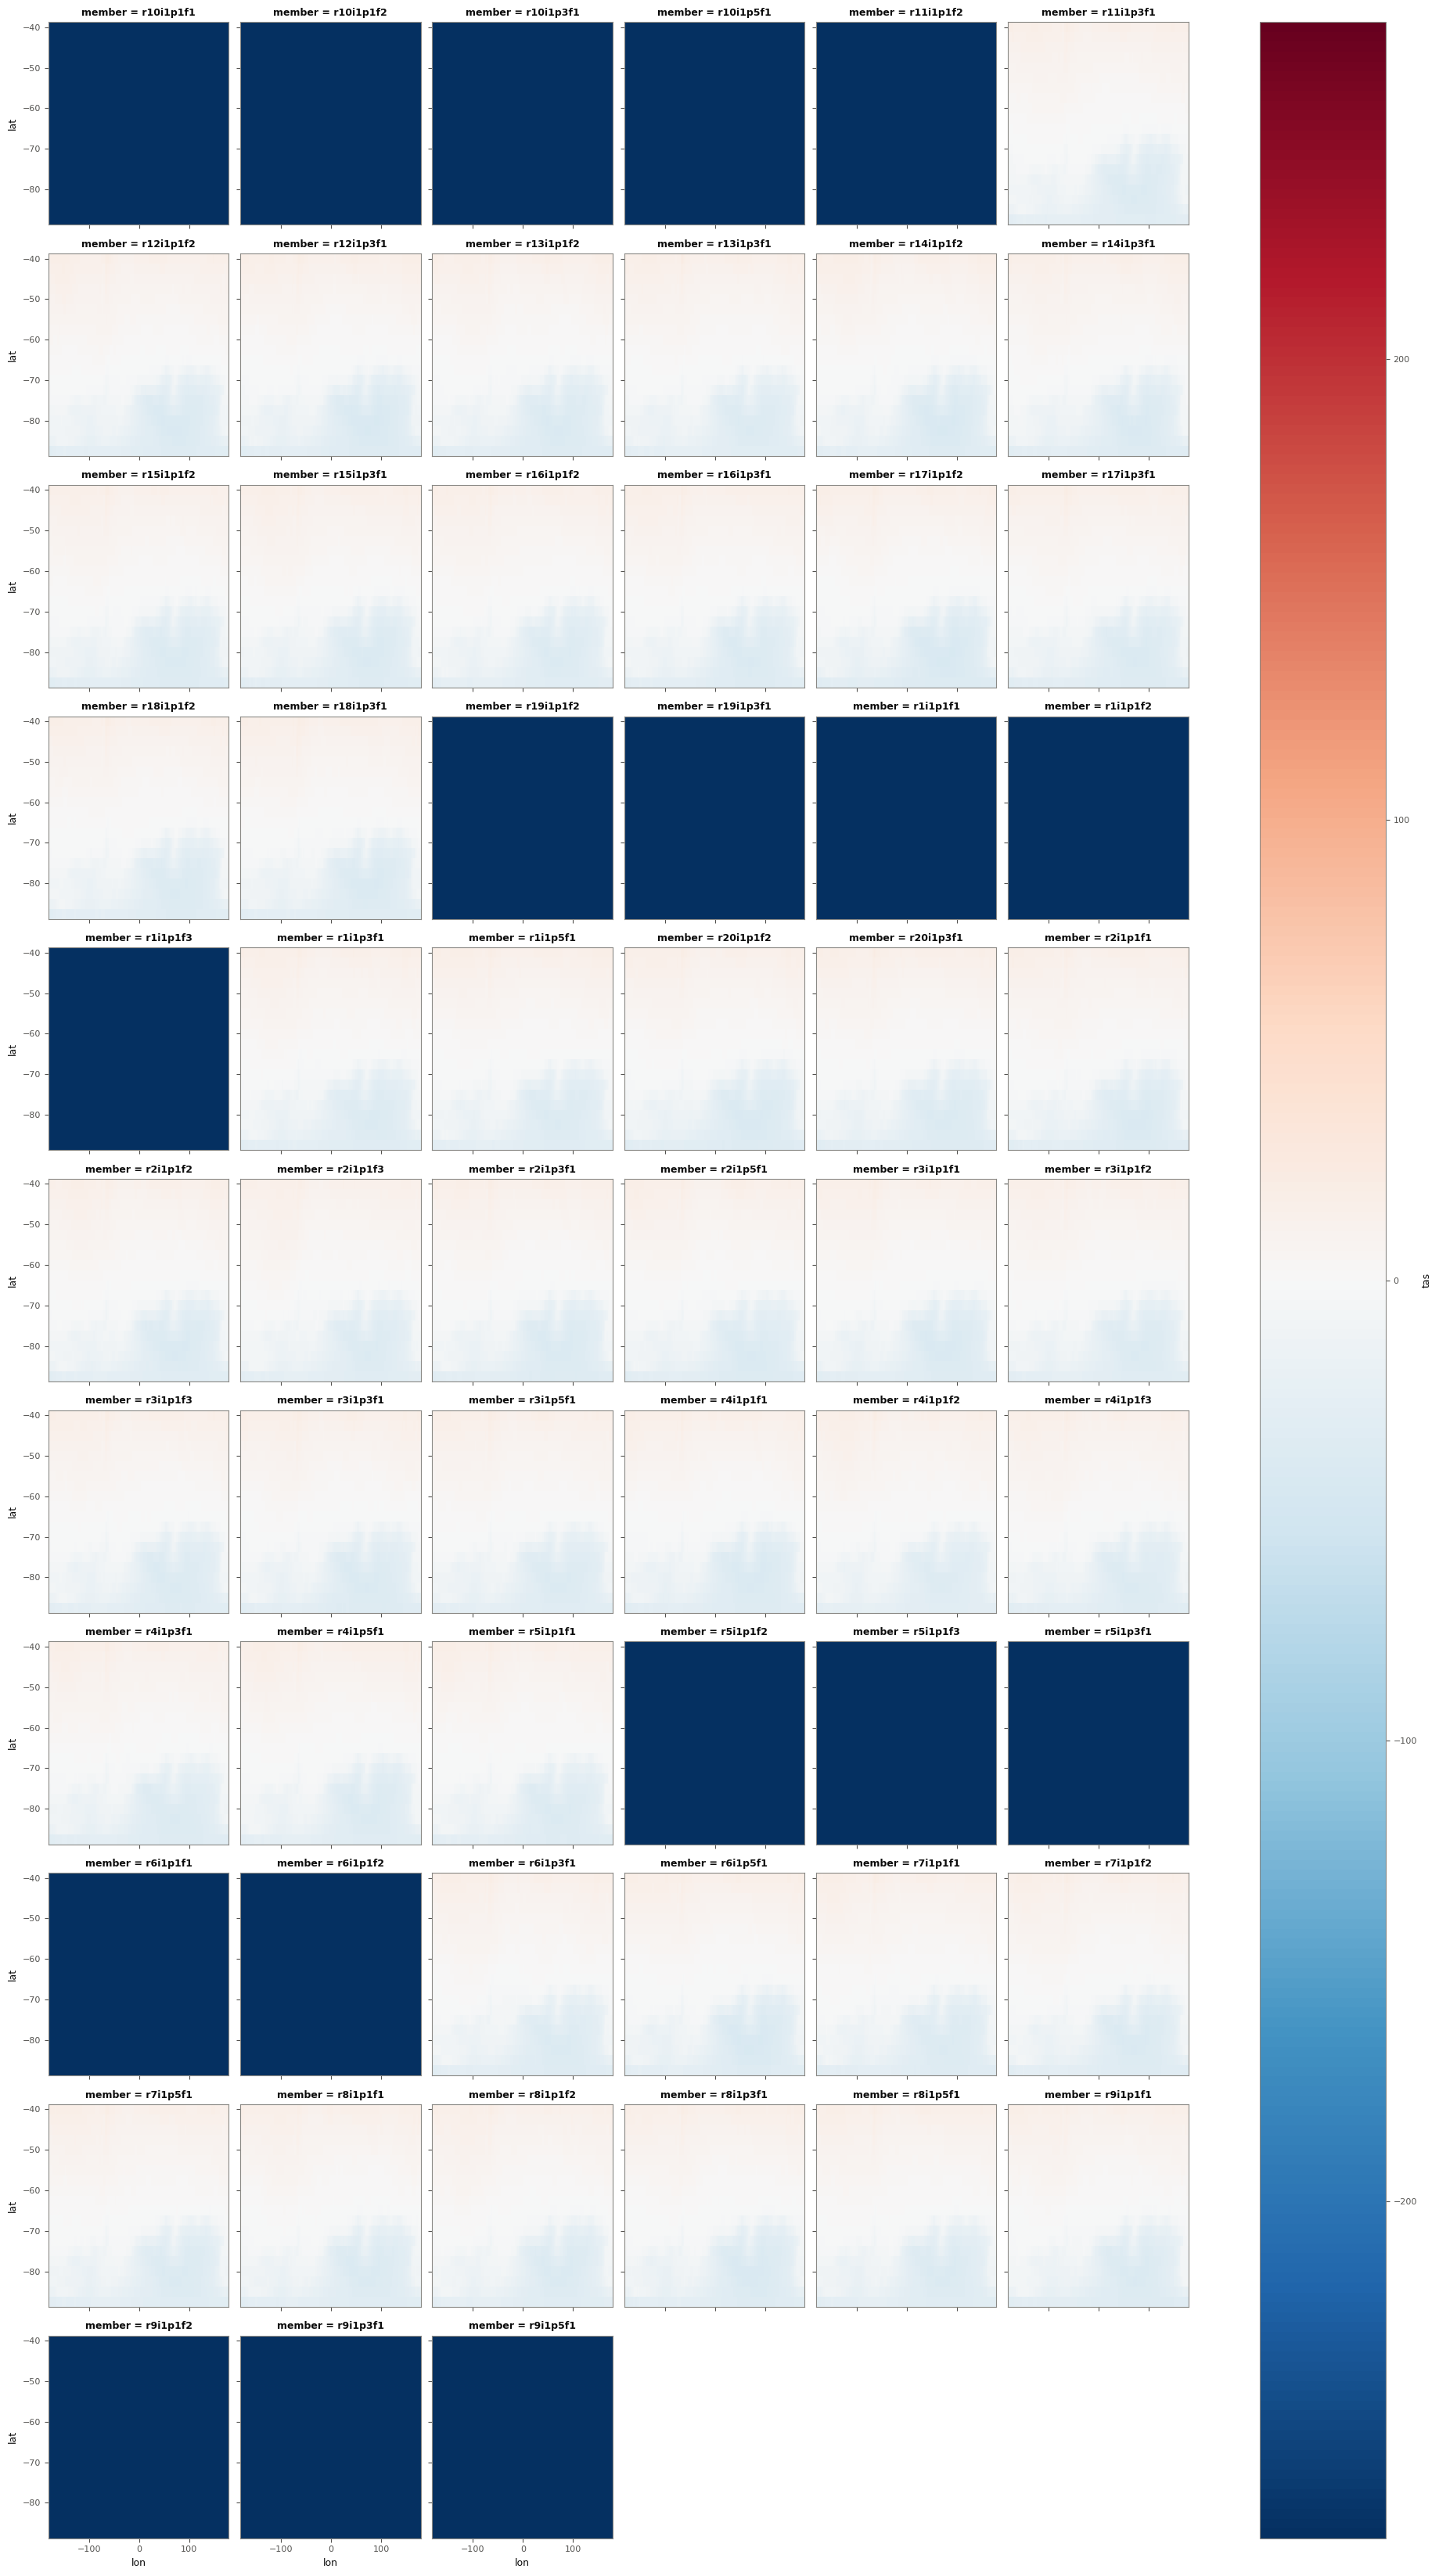

In [37]:
lesfmip_season_tree['GISS-E2-1-G']['historical'].tas.isel(season=0, year=0).plot(col='member', col_wrap=6)

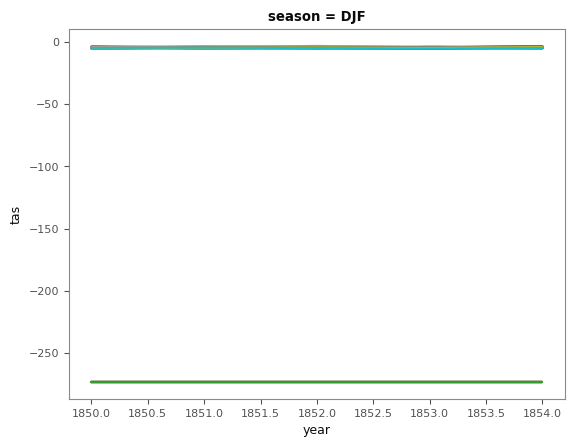

In [28]:
lesfmip_season_tree['GISS-E2-1-G']['historical'].tas.isel(season=0, year=slice(0, 5)).mean(dim=['lat', 'lon']).plot(hue='member', add_legend=False);

### What was opened

Whichever section ran. An empty square is a model and experiment that was never opened.

In [13]:
#(t): Members per model (rows) and experiment (columns)
member_counts_df = pd.Series({(node.parent.name, node.name): node.sizes['member']
                              for node in lesfmip_season_tree.leaves}).unstack()
member_counts_df = member_counts_df.reindex(columns=MAIN_EXPERIMENTS)

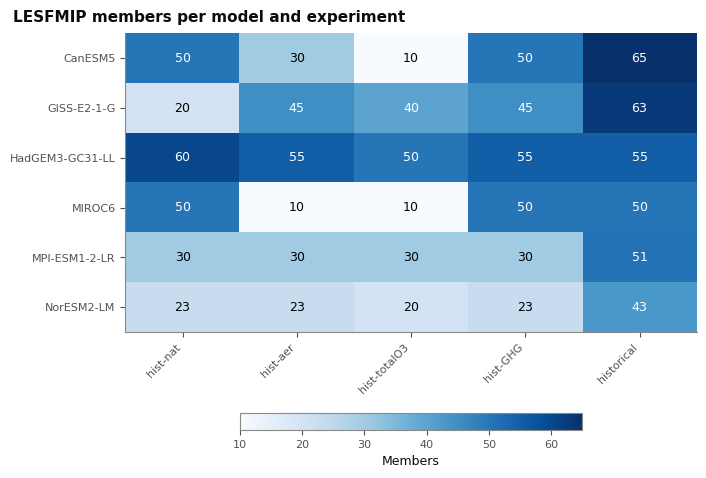

In [14]:
#(t): The members: each model (rows) and experiment (columns), grey where there are none
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.9 * member_counts_df.shape[1] + 0.5,
                                                  panel_height=0.4 * member_counts_df.shape[0] + 0.3, left_margin=1.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
counts_image = methods.plot_member_counts(member_counts_df, ax=axes[0, 0])
fig.colorbar(counts_image, ax=axes, location='bottom', shrink=0.6, label='Members')
fig.suptitle('LESFMIP members per model and experiment', x=0.01, ha='left');

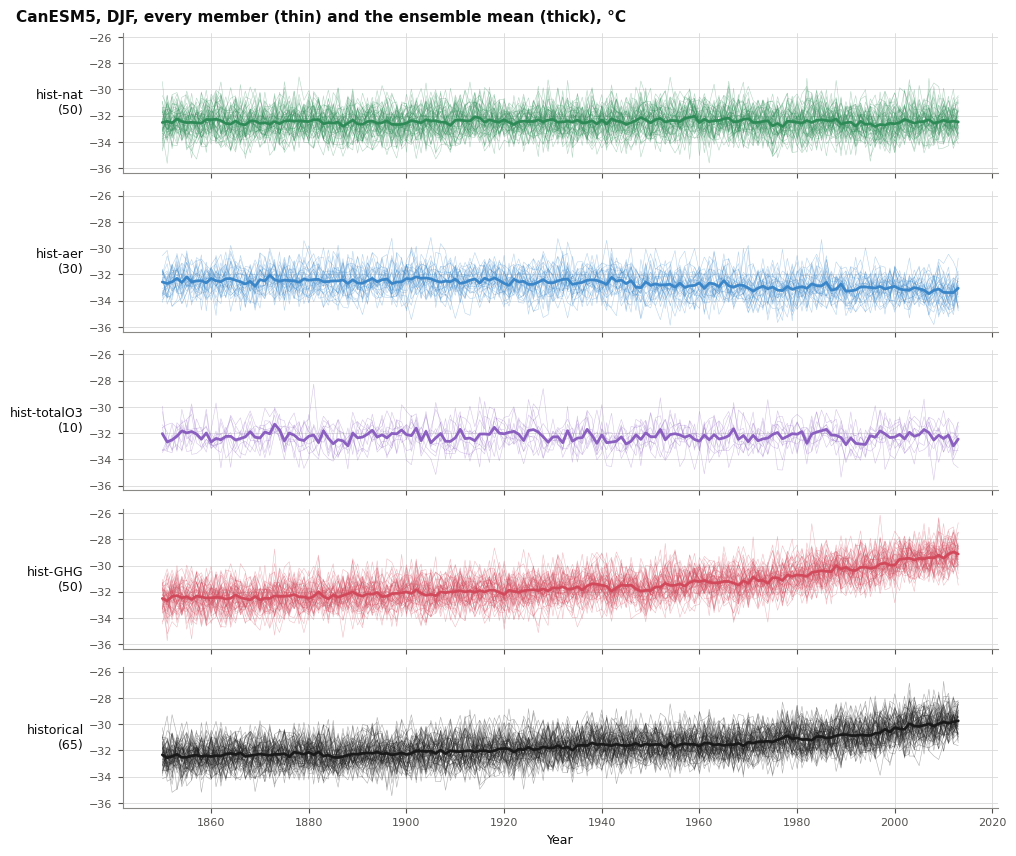

In [15]:
#(t): Each experiment's members at the point (one model, DJF): every member (thin) and the ensemble mean (thick), one
#(t): row each, the number of members beside it
model_point_tree = lesfmip_season_tree[EXAMPLE_MODEL].sel(**SAMPLE_LAT_LON).load()
point_experiments = [e for e in MAIN_EXPERIMENTS if e in model_point_tree.children]
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(point_experiments), n_cols=1, n_legends=0,
                                                  panel_width=8.5, panel_height=1.0, left_margin=1.4),
                 layout='constrained')
axes = fig.add_gridspec(len(point_experiments), 1).subplots(sharex=True, sharey=True, squeeze=False)
for ax, experiment in zip(axes[:, 0], point_experiments):
    experiment_members_da = model_point_tree[experiment][VARIABLE.name].sel(season='DJF')
    charts.plot_lines(experiment_members_da, 'year', ax=ax, color=FORCING_COLORS[experiment], linewidth=0.4, alpha=0.35)
    charts.plot_lines(experiment_members_da.mean('member'), 'year', ax=ax, color=FORCING_COLORS[experiment],
                      linewidth=2)
    ax.set_ylabel(f"{experiment}\n({experiment_members_da.sizes['member']})", rotation=0, ha='right', va='center')
axes[-1, 0].set_xlabel('Year')
fig.suptitle(f'{EXAMPLE_MODEL}, DJF, every member (thin) and the ensemble mean (thick), {VARIABLE.units}', x=0.01,
             ha='left');

## Climatologies

Every season: the 1979–2013 average (the climatology) and the year-to-year spread of ERA5 and of each model's historical ensemble, how they differ, the area mean through time, and one model's experiments. The models' climatology minus ERA5's is the mean-state bias, which only the tests of raw values see; every other test removes it.

### ERA5

In [201]:
#(t): ERA5's climatology: its mean over SATELLITE_YEAR_RANGE in each season, on (season, lat, lon)
era5_climatology_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE, season=SEASONS).mean('year')
era5_climatology_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4)> Size: 46kB
-29.67 -44.06 -47.49 -40.89 -29.48 -43.8 ... 9.007 11.59 17.23 15.03 10.95 12.92
Coordinates:
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5

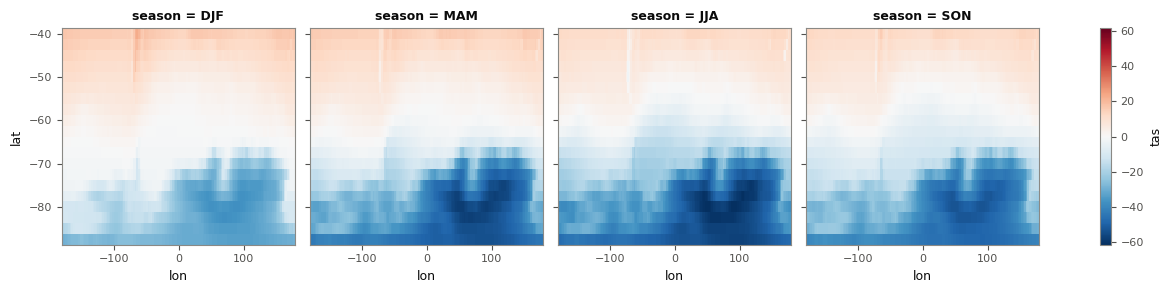

In [202]:
era5_climatology_da.plot(x='lon', y='lat', col='season', cmap='RdBu_r');

In [203]:
#(t): ERA5's year-to-year spread: the standard deviation of its seasonal means over SATELLITE_YEAR_RANGE
era5_spread_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE, season=SEASONS).std('year')

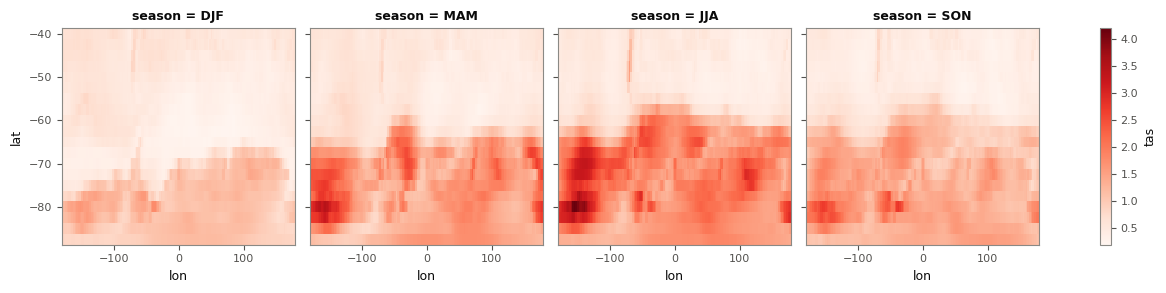

In [204]:
era5_spread_da.plot(x='lon', y='lat', col='season', cmap='Reds');

In [205]:
#(t): ERA5 south of 60°S
era5_south_da = era5_seasonal_da.sel(season=SEASONS, lat=slice(None, -60))

In [206]:
#(t): its area mean in every year (cos-latitude weighted)
era5_area_weights_da = np.cos(np.deg2rad(era5_south_da.lat))
era5_area_mean_da = era5_south_da.weighted(era5_area_weights_da).mean(['lat', 'lon'])

### Historical ensembles

In [207]:
#(t): Each model's historical ensemble
historical_tree = lesfmip_season_tree.match('*/historical')

In [208]:
#(t): over SATELLITE_YEAR_RANGE, in the seasons' order
historical_eval_tree = historical_tree.sel(year=SATELLITE_YEAR_RANGE, season=SEASONS)

In [209]:
#(t): Each model's climatology: the mean over the years and the members
historical_climatology_tree = historical_eval_tree.mean(['year', 'member'])

In [210]:
%%time
#(t): In one DataArray, on (model, season, lat, lon)
historical_climatology_ds = datatree.tree_to_dataset(historical_climatology_tree, dims=['model', 'experiment']).load()
historical_climatology_da = historical_climatology_ds[VARIABLE.name].sel(experiment='historical', drop=True)
historical_climatology_da

CPU times: user 3.58 s, sys: 6.83 s, total: 10.4 s
Wall time: 1.96 s


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6)> Size: 276kB
-25.62 -99.11 -27.64 -19.52 -28.13 -28.86 ... -68.89 13.03 14.82 11.93 14.17
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'

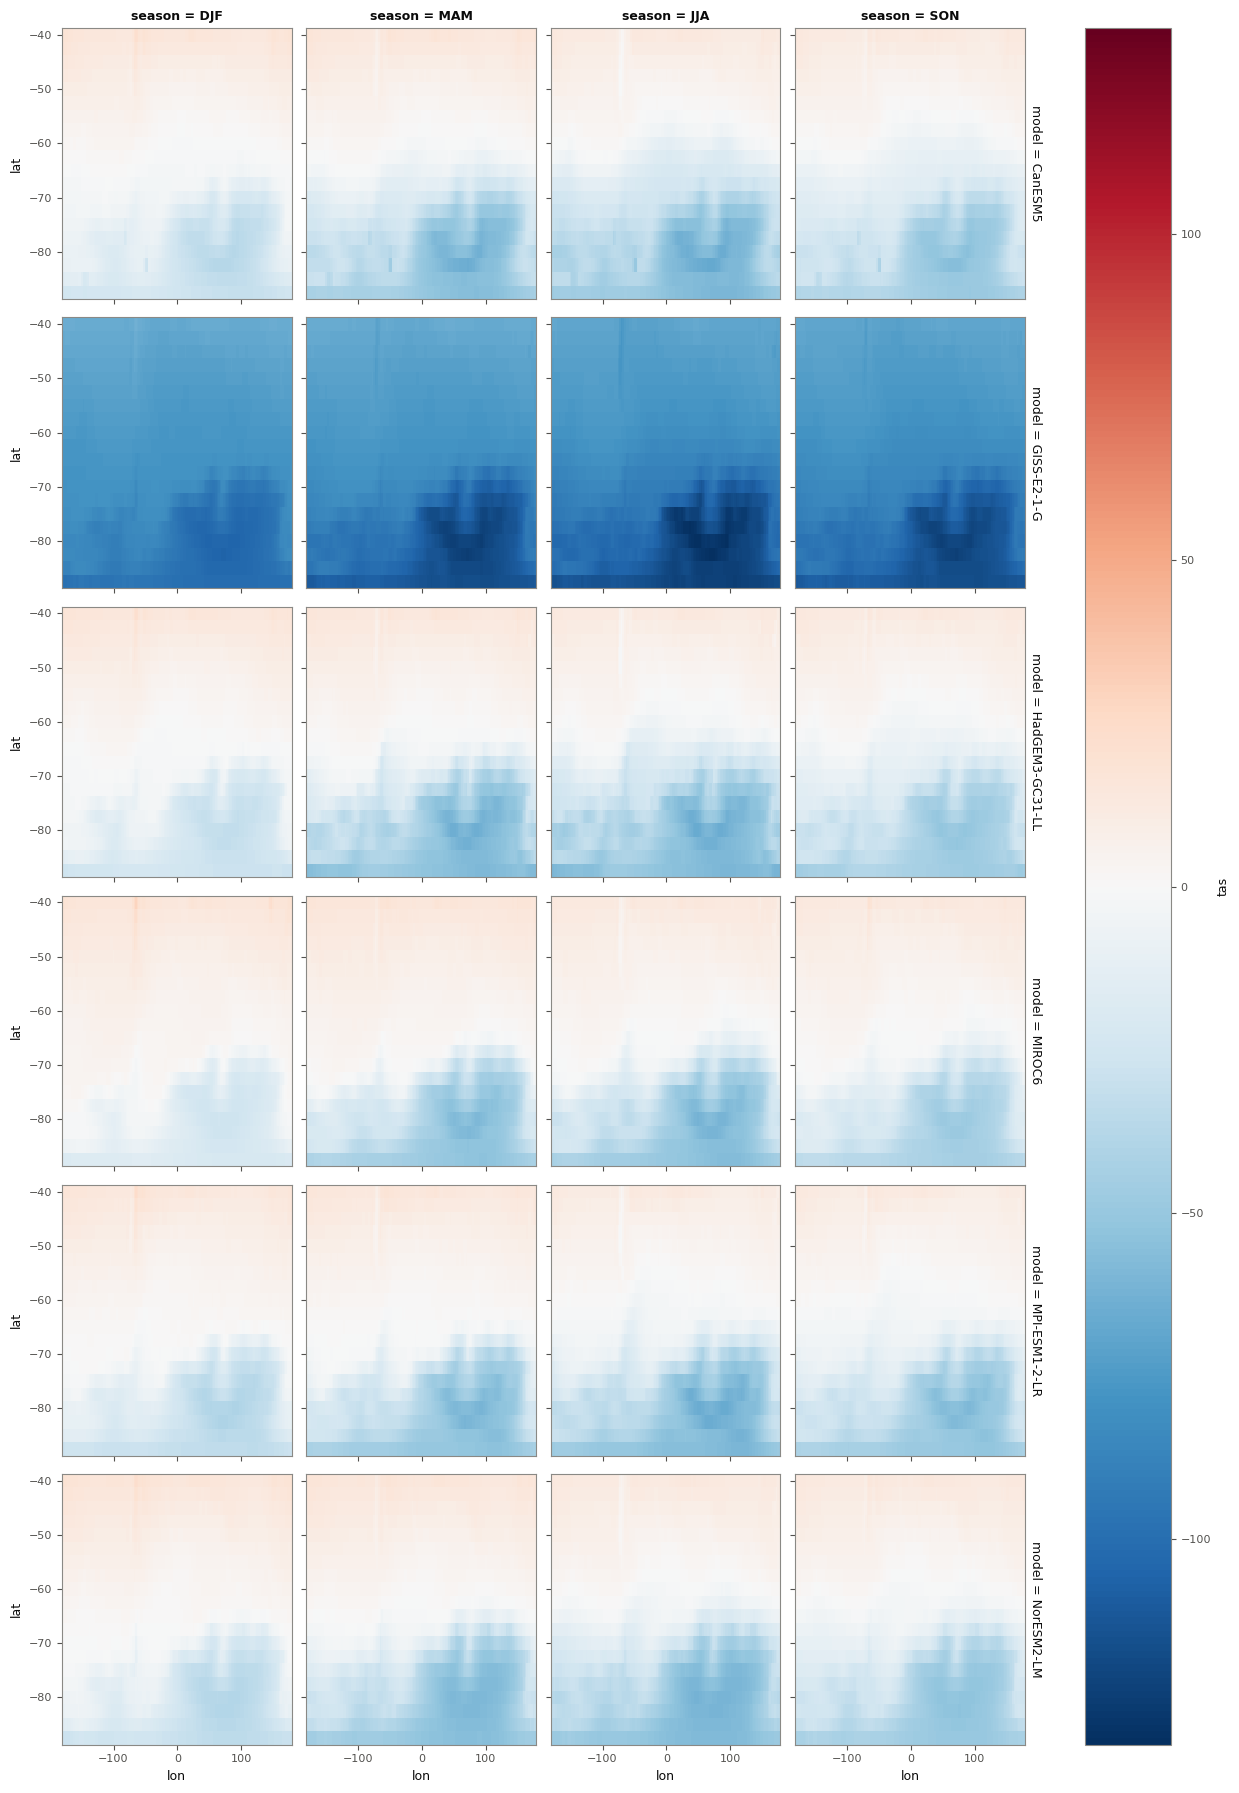

In [211]:
historical_climatology_da.plot(x='lon', y='lat', row='model', col='season', cmap='RdBu_r');

In [212]:
#(t): Each model's climatology minus ERA5's
historical_bias_da = historical_climatology_da - era5_climatology_da

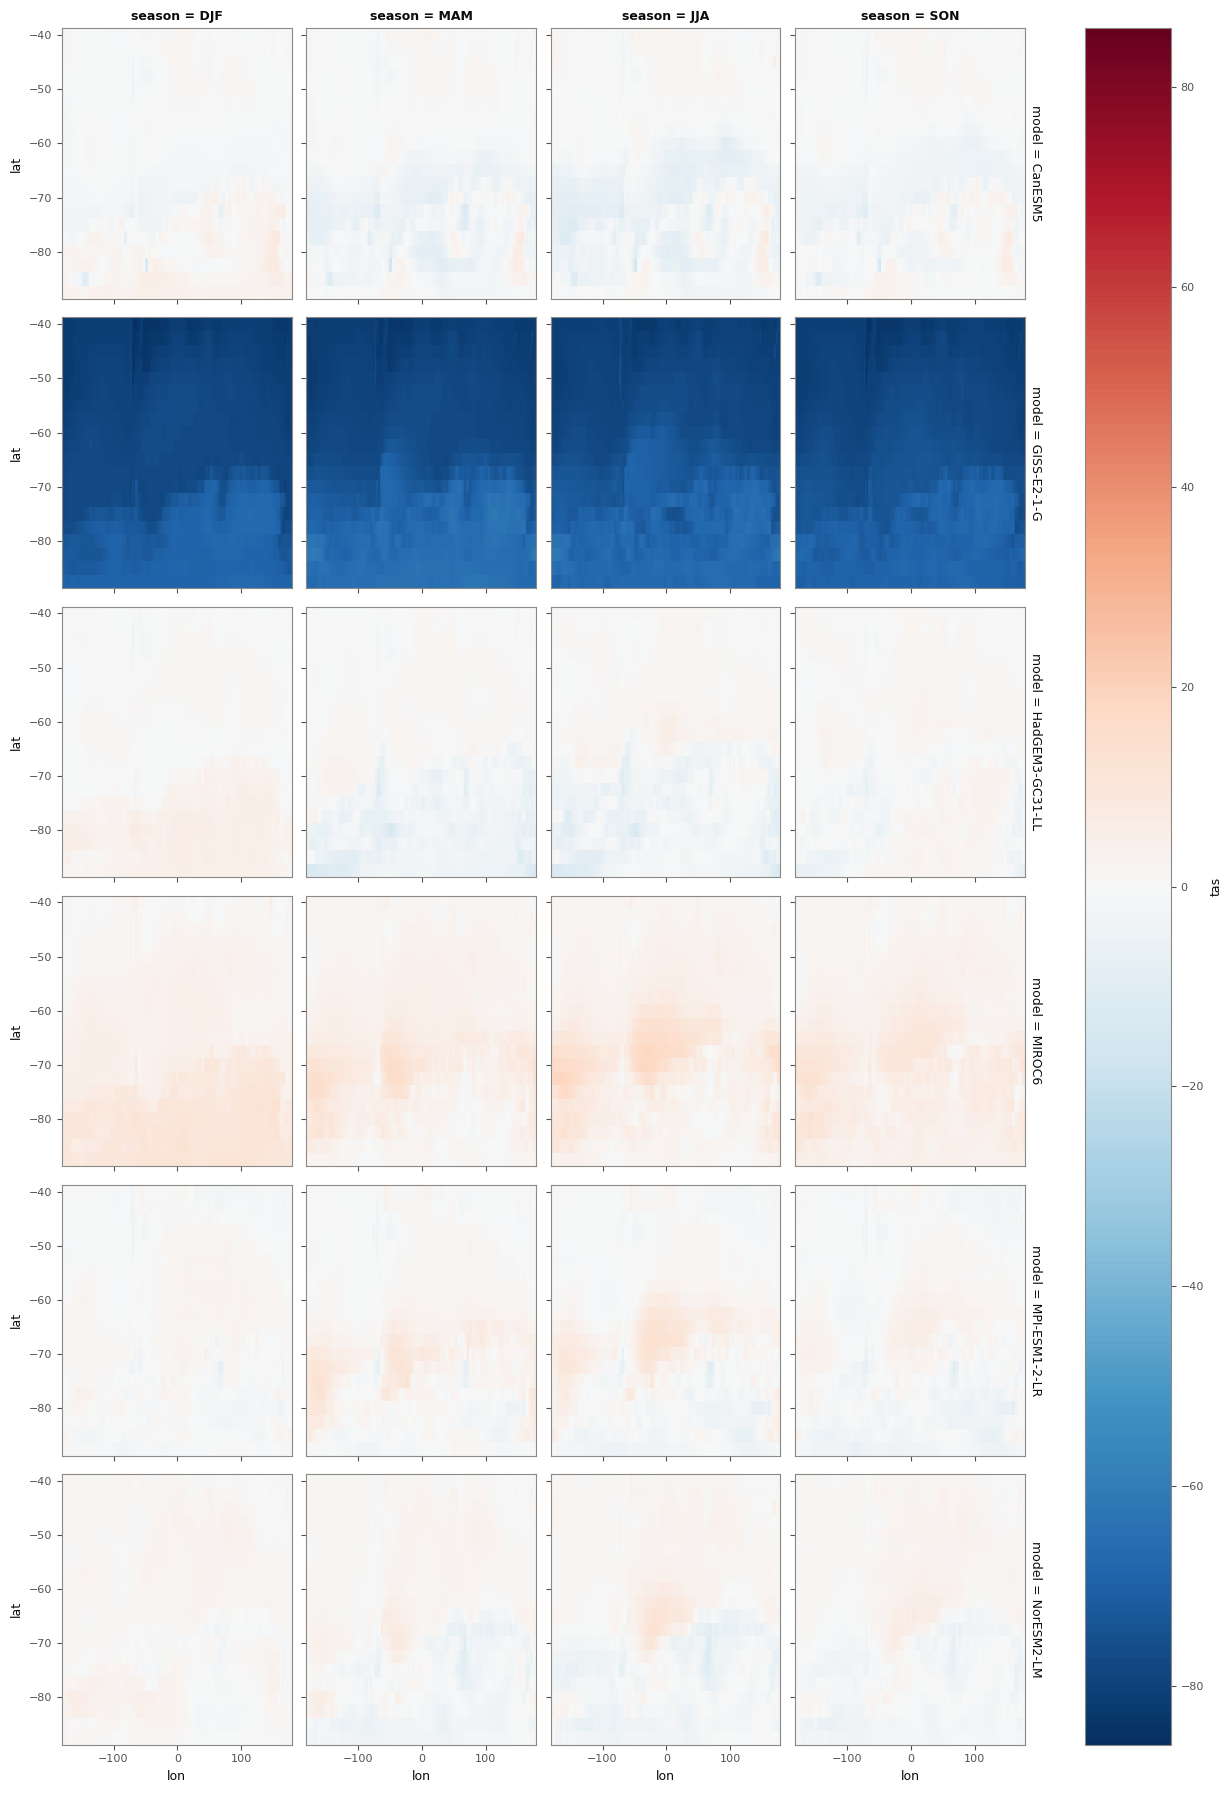

In [213]:
historical_bias_da.plot(x='lon', y='lat', row='model', col='season', cmap='RdBu_r', center=0);

In [214]:
#(t): ERA5's climatology and each model's bias together, for plot_01a's first look (polar maps)
first_look_ds = xr.Dataset({'era5_mean': era5_climatology_da, 'model_bias': historical_bias_da})
first_look_ds

<xarray.Dataset> Size: 324kB
Dimensions:     (lat: 20, season: 4, lon: 144, model: 6)
Coordinates:
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
Data variables:
    era5_mean   (lat, lon, season) float32 46kB -29.67 -44.06 ... 10.95 12.92
    model_bias  (lat, lon, season, model) float32 276kB 4.043 -69.45 ... 1.254

In [215]:
#(t): Saved for plot_01a
first_look_path = RESULTS_DIR / 'first_look.zarr'
first_look_ds.to_zarr(first_look_path, mode='w')
first_look_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/first_look.zarr')

In [216]:
#(t): Each member's year-to-year standard deviation
historical_member_spread_tree = historical_eval_tree.std('year')

In [217]:
#(t): averaged over the members
historical_spread_tree = historical_member_spread_tree.mean('member')

In [218]:
%%time
#(t): In one DataArray, on (model, season, lat, lon)
historical_spread_ds = datatree.tree_to_dataset(historical_spread_tree, dims=['model', 'experiment']).load()
historical_spread_da = historical_spread_ds[VARIABLE.name].sel(experiment='historical', drop=True)

CPU times: user 4.67 s, sys: 6.48 s, total: 11.1 s
Wall time: 1.83 s


In [219]:
#(t): Each model's spread over ERA5's: above 1, the model varies more from year to year than ERA5
historical_spread_ratio_da = historical_spread_da / era5_spread_da

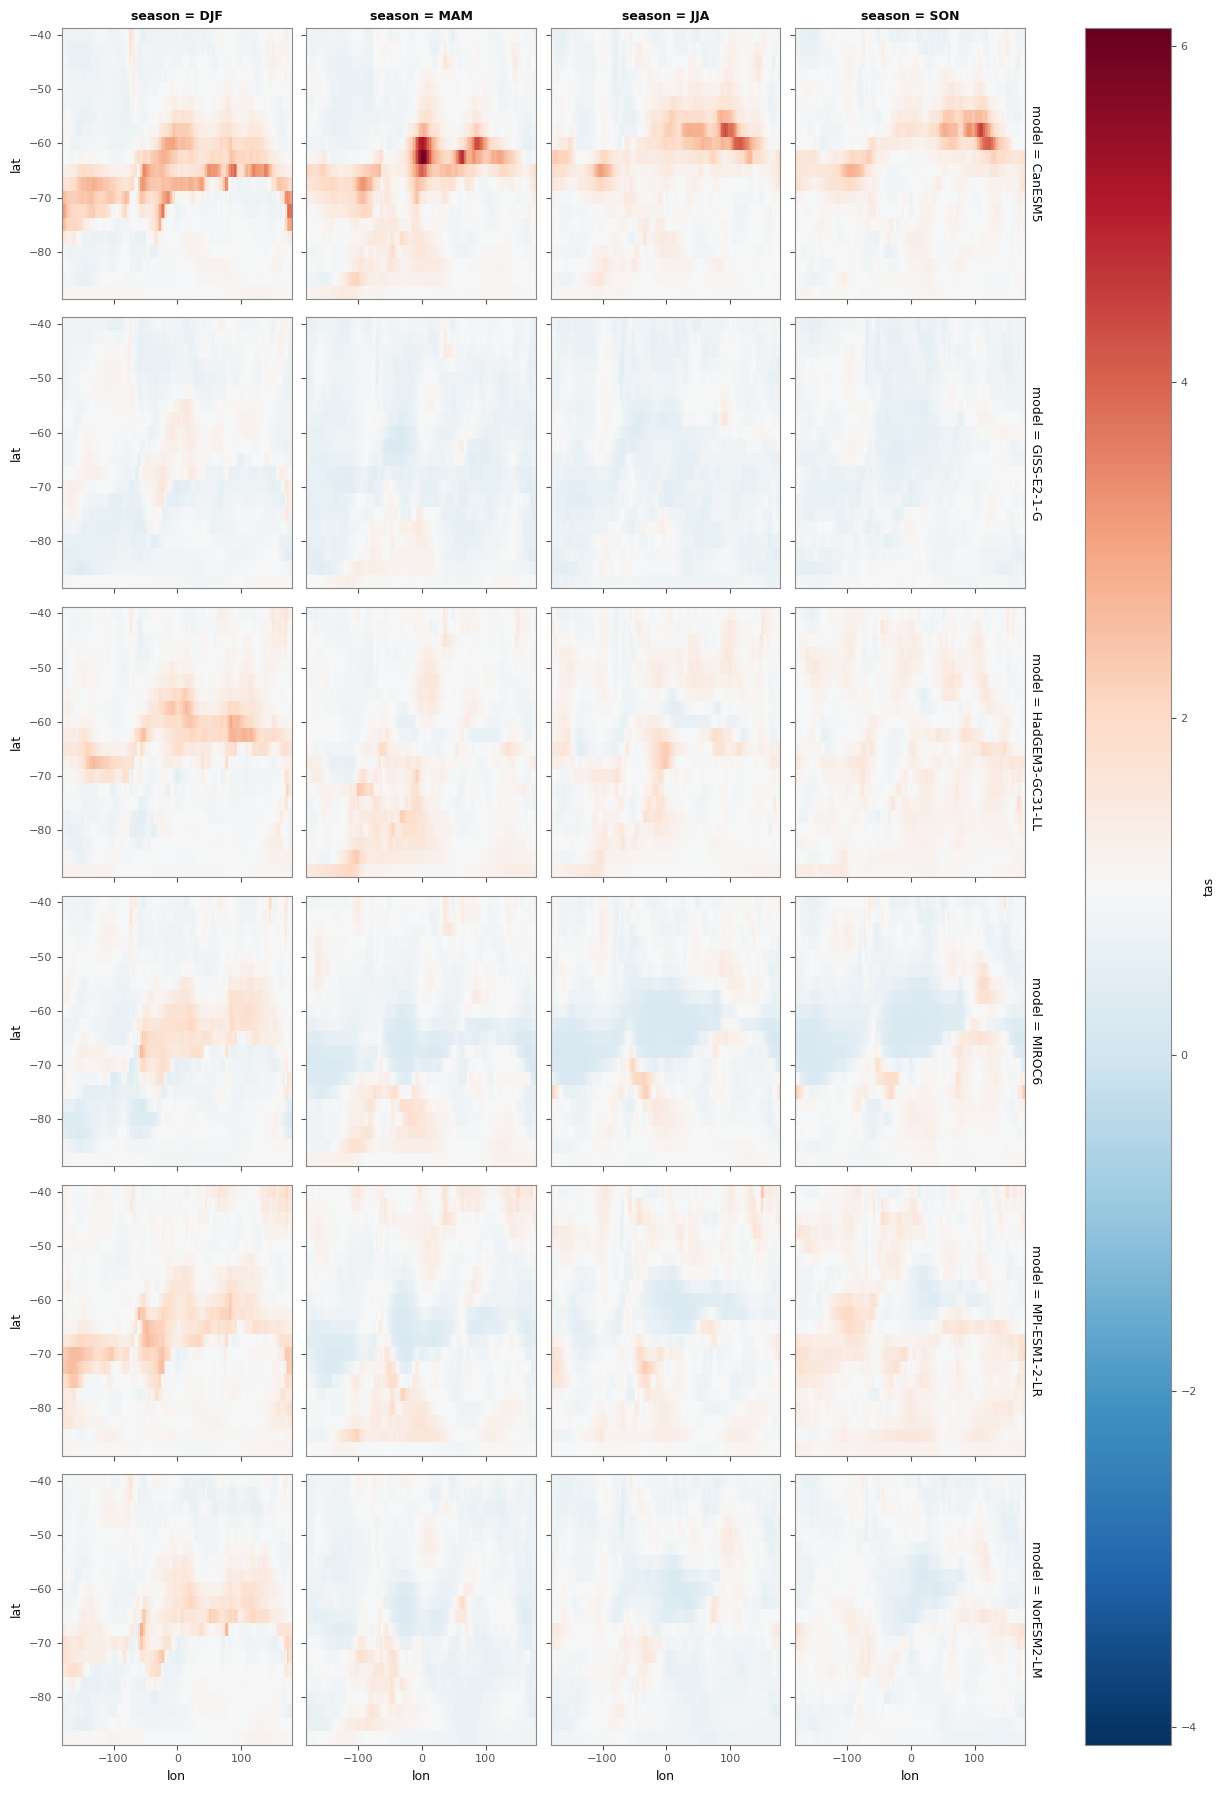

In [220]:
historical_spread_ratio_da.plot(x='lon', y='lat', row='model', col='season', cmap='RdBu_r', center=1);

In [221]:
#(t): Each model's historical ensemble mean, every year
historical_ensemble_mean_tree = historical_tree.mean('member')

In [222]:
#(t): In one DataArray, on (model, year, season, lat, lon)
historical_ensemble_mean_ds = datatree.tree_to_dataset(historical_ensemble_mean_tree, dims=['model', 'experiment'])
historical_ensemble_mean_da = historical_ensemble_mean_ds[VARIABLE.name].sel(experiment='historical', drop=True)

In [223]:
#(t): south of 60°S, in the seasons' order
historical_south_da = historical_ensemble_mean_da.sel(season=SEASONS, lat=slice(None, -60))

In [224]:
%%time
#(t): its area mean in every year (cos-latitude weighted)
historical_area_weights_da = np.cos(np.deg2rad(historical_south_da.lat))
historical_area_mean_da = historical_south_da.weighted(historical_area_weights_da).mean(['lat', 'lon']).load()

CPU times: user 2.74 s, sys: 5.21 s, total: 7.96 s
Wall time: 1.46 s


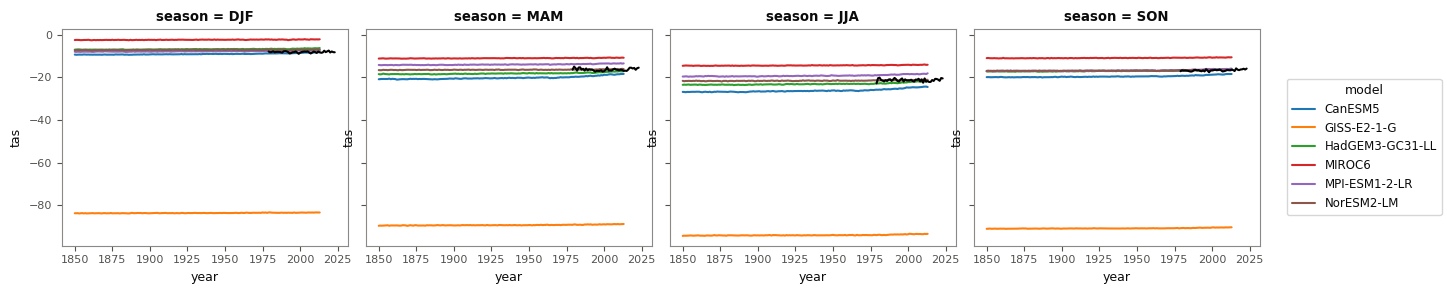

In [225]:
#(t): The models' ensemble means (colours) and ERA5 (black), one panel per season
fg = historical_area_mean_da.plot(x='year', hue='model', col='season')
for ax, season in zip(fg.axs.flat, SEASONS):
    era5_area_mean_da.sel(season=season).plot(ax=ax, color='k')

### One model's experiments

In [226]:
#(t): EXAMPLE_MODEL's every experiment, over SATELLITE_YEAR_RANGE, in the seasons' order
model_eval_tree = lesfmip_season_tree[EXAMPLE_MODEL].sel(year=SATELLITE_YEAR_RANGE, season=SEASONS)

In [227]:
#(t): Each experiment's climatology: the mean over the years and the members
model_climatology_tree = model_eval_tree.mean(['year', 'member'])

In [228]:
%%time
#(t): In one DataArray, on (experiment, season, lat, lon)
model_climatology_ds = datatree.tree_to_dataset(model_climatology_tree, dims=['experiment']).load()
model_climatology_da = model_climatology_ds[VARIABLE.name]

CPU times: user 2.44 s, sys: 3.79 s, total: 6.23 s
Wall time: 1.15 s


In [229]:
#(t): Each experiment's climatology minus hist-nat's, over the same years
model_difference_da = model_climatology_da - model_climatology_da.sel(experiment='hist-nat')

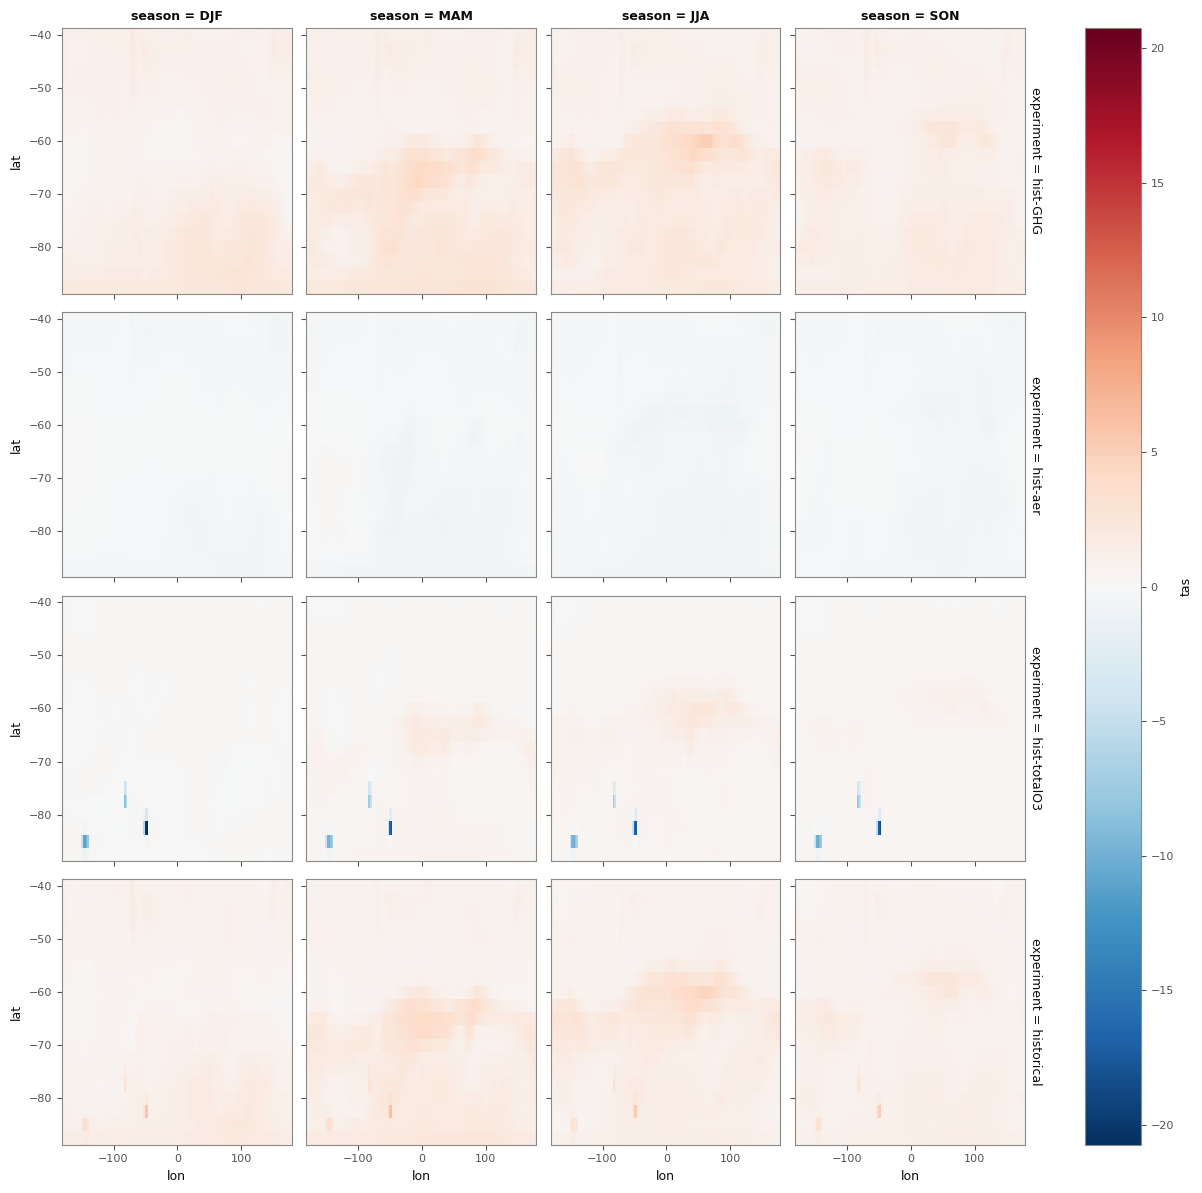

In [230]:
#(t): Quick look: each experiment's climatology minus hist-nat's, every season
model_difference_da.drop_sel(experiment='hist-nat').plot(x='lon', y='lat', row='experiment', col='season',
                                                         cmap='RdBu_r', center=0);

# Part 1: Is Each Model Consistent with ERA5?

Every test asks one question: *could ERA5 be one more member of the historical ensemble?* If a model simulates both the forced response (the **signal**) and the internal variability (the **noise**) correctly, ERA5 is statistically indistinguishable from any one member. So each test works out the same statistic for ERA5 and for every member, then asks where ERA5's value falls among the members' (Suarez-Gutierrez, Milinski & Maher, 2021, *Clim. Dyn.*, [doi:10.1007/s00382-021-05821-w](https://doi.org/10.1007/s00382-021-05821-w)). The members are the null distribution, so no shape is assumed, and each member is exactly as long as ERA5.

This notebook does the first half: the statistic of every member and of ERA5. Each statistic has its own section, with the same three steps:

1. **The example**: EXAMPLE_MODEL's members and ERA5 at `SAMPLE_LAT_LON` in DJF, with a figure of what goes in and what comes out.
2. **Every model, every grid point**: the same line, on every model's members and on ERA5, at every grid point and in every season.
3. **Saved as it is**, into one store, `statistics.zarr`, as a variable named after the statistic: every member's value in `/<model>/historical` (on member × season × lat × lon) and ERA5's in `/ERA5` (on season × lat × lon). Each save adds its statistic to the store (zarr's append mode, `mode='a'`) and leaves the others as they are, so rerunning one section replaces only its statistic. A statistic taken out of this notebook stays in the store until the store is deleted.

The second half, where ERA5's value falls among the members', is worked out from these saves where it is used: notebooks plot_01a to plot_01c (at the point and on the maps, with the field test) and plot_06, and calc_03b's table. The rank histograms are in notebook calc_03b.

In [ ]:
#(t): The one store every statistic below is saved into
statistics_path = RESULTS_DIR / 'statistics.zarr'
statistics_path

## The Data

Every model's historical members and ERA5 over `SATELLITE_YEAR_RANGE`, at every grid point. The models stay in a DataTree, each with its own members; ERA5 is one DataArray. On the full data nothing is loaded yet: each statistic is worked out, block by block, when it is saved.

In [231]:
#(t): LESFMIP over the years shared with ERA5
lesfmip_obs_tree = lesfmip_season_tree.sel(year=SATELLITE_YEAR_RANGE)

In [232]:
#(t): Each model's historical members at every grid point, on (member, year, season, lat, lon)
historical_tree = lesfmip_obs_tree.match('*/historical')

In [233]:
#(t): ERA5 over the same years, on (year, season, lat, lon)
era5_obs_da = era5_seasonal_da.sel(year=SATELLITE_YEAR_RANGE)

In [1]:
historical_tree

NameError: name 'historical_tree' is not defined

### At the point

The same data at `SAMPLE_LAT_LON`: the examples below are taken from it, and plot_01a draws its distributions and plumes from it.

In [234]:
#(t): Each model's historical members at the point, on (member, year, season)
historical_point_tree = historical_tree.sel(SAMPLE_LAT_LON).load()
historical_point_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 36kB -31.74 -57.74 ... -52.73 -45.67
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (member: 63, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 35kB -273.1 -273.1 ... -273.1 -273.1
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (member: 43, year: 35, season: 4)
│           Coordinates:
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lon      float64 8B 120.0
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 24kB -32.66 -58.42 ... -54.74 -49.95
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (member: 55, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, year, season) float32 31kB -27.72 -57.56 ... -51.74 -43.94
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (member: 50, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 28kB -22.22 -52.98 ... -48.27 -41.32
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (member: 51, year: 35, season: 4)
            Coordinates:
                lon      float64 8B 120.0
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
                lat      float64 8B -82.5
              * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, year, season) float32 29kB -34.95 -56.32 ... -52.23 -47.02

In [235]:
#(t): ERA5 at the point, on (year, season)
era5_point_da = era5_obs_da.sel(SAMPLE_LAT_LON)
era5_point_da

<xarray.DataArray 'tas' (year: 35, season: 4)> Size: 560B
-32.97 -55.57 -51.88 -45.79 -33.46 -53.79 ... -46.57 -33.87 -50.94 -51.86 -43.27
Coordinates:
    lat      float64 8B -82.5
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
    lon      float64 8B 120.0
  * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013

In [236]:
#(t): Check: every model has the same years as ERA5, and nothing is missing (the tests compare the same samples)
{node.parent.name: (int(node.year.min()), int(node.year.max()), int(node[VARIABLE.name].isnull().sum()))
 for node in historical_point_tree.leaves}, (int(era5_point_da.year.min()), int(era5_point_da.year.max()),
                                             int(era5_point_da.isnull().sum()))

({'CanESM5': (1979, 2013, 0),
  'GISS-E2-1-G': (1979, 2013, 0),
  'NorESM2-LM': (1979, 2013, 0),
  'HadGEM3-GC31-LL': (1979, 2013, 0),
  'MIROC6': (1979, 2013, 0),
  'MPI-ESM1-2-LR': (1979, 2013, 0)},
 (1979, 2013, 0))

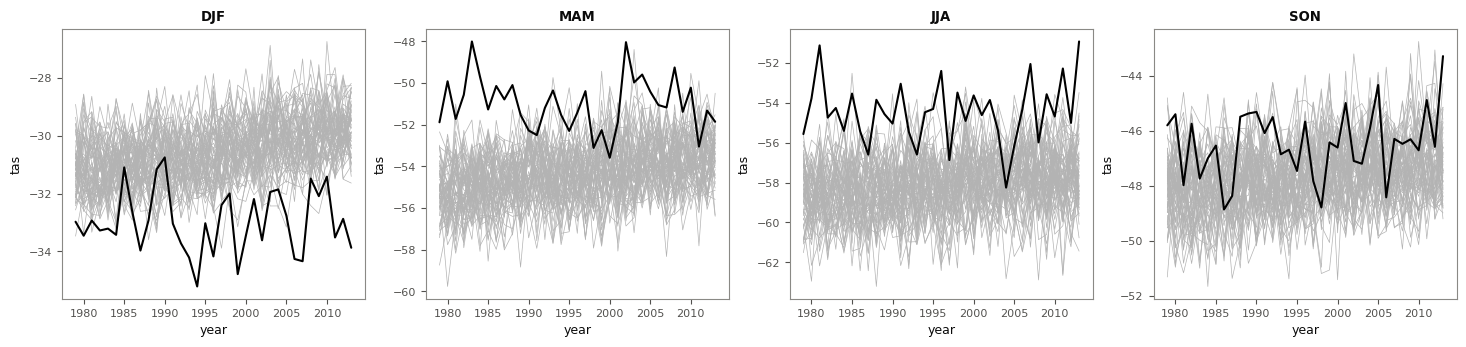

In [237]:
#(t): Quick look: EXAMPLE_MODEL's members (grey) and ERA5 (black), every season
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharex=True)
for ax, season in zip(axes, SEASONS):
    historical_point_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].sel(season=season).plot.line(ax=ax, x='year',
                                                                                           hue='member',
                                                                                    add_legend=False, color='0.7', lw=0.5)
    era5_point_da.sel(season=season).plot(ax=ax, color='k')
    ax.set_title(season)

In [238]:
#(t): Each model's hist-nat members at the point too, as context for plot_01a's time series
histnat_point_tree = lesfmip_obs_tree.match('*/hist-nat').sel(SAMPLE_LAT_LON).load()
histnat_point_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/hist-nat
│           Dimensions:  (member: 50, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│             * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, year, season) float32 28kB -30.76 -61.05 ... -58.24 -49.38
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/hist-nat
│           Dimensions:  (member: 20, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat      float64 8B -82.5
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│             * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│           Data variables:
│               tas      (member, year, season) float32 11kB -32.84 -61.18 ... -55.29 -52.48
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/hist-nat
│           Dimensions:  (member: 23, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│               lat      float64 8B -82.5
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, year, season) float32 13kB -34.6 -57.85 ... -54.57 -49.5
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/hist-nat
│           Dimensions:  (member: 60, year: 35, season: 4)
│           Coordinates:
│               lon      float64 8B 120.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat      float64 8B -82.5
│             * member   (member) object 480B 'r10i1p1f3' 'r11i1p1f3' ... 'r9i1p1f3'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, year, season) float32 34kB -28.42 -56.83 ... -55.54 -44.74
├── Group: /MIROC6
│   └── Group: /MIROC6/hist-nat
│           Dimensions:  (member: 50, year: 35, season: 4)
│           Coordinates:
│               lat      float64 8B -82.5
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
│               lon      float64 8B 120.0
│           Data variables:
│               tas      (member, year, season) float32 28kB -23.61 -57.93 ... -53.11 -44.45
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/hist-nat
            Dimensions:  (member: 30, year: 35, season: 4)
            Coordinates:
                lon      float64 8B 120.0
              * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
                lat      float64 8B -82.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
              * member   (member) object 240B 'r10i1p1f2' 'r11i1p1f2' ... 'r9i1p1f2'
            Data variables:
                tas      (member, year, season) float32 17kB -36.47 -62.35 ... -56.92 -52.0

In [239]:
#(t): Saved for plot_01a and plot_01b: each model's historical members at the point
historical_point_path = RESULTS_DIR / 'historical_point.zarr'
historical_point_tree.to_zarr(historical_point_path, mode='w')
historical_point_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/historical_point.zarr')

In [240]:
#(t): ... their hist-nat members
histnat_point_path = RESULTS_DIR / 'histnat_point.zarr'
histnat_point_tree.to_zarr(histnat_point_path, mode='w')
histnat_point_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/histnat_point.zarr')

In [241]:
#(t): ... and ERA5
era5_point_path = RESULTS_DIR / 'era5_point.zarr'
era5_point_da.to_dataset(name=VARIABLE.name).to_zarr(era5_point_path, mode='w')
era5_point_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/era5_point.zarr')

### The example

Every statistic below is worked out on these two first: EXAMPLE_MODEL's members at the point in DJF, and ERA5's.

In [242]:
#(t): EXAMPLE_MODEL's members at the point in DJF, on (member, year)
example_members_da = historical_point_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].sel(season='DJF')

In [243]:
#(t): ... and ERA5's, on (year)
example_era5_da = era5_point_da.sel(season='DJF')

## Detrended Values

The mean and the trend are of the raw values. The other six statistics are of each series' **detrended** values: every member and ERA5, in each season, minus its own least-squares straight line through 1979–2013 (`ev.detrend`). What is left is the year-to-year variability, so the warming over the record neither widens the spread nor bends the shape. Every series loses its own line in the same way, so the comparison stays fair.

In [244]:
#(t): The example: each member minus its own straight line through the years
example_members_detrended_da = ev.detrend(example_members_da)

In [245]:
#(t): ... and ERA5 minus its own
example_era5_detrended_da = ev.detrend(example_era5_da)

In [246]:
#(t): The straight line each series lost: the series minus its detrended values, for ERA5 and the first member
example_era5_line_da = example_era5_da - example_era5_detrended_da
example_first_line_da = example_members_da.isel(member=0) - example_members_detrended_da.isel(member=0)

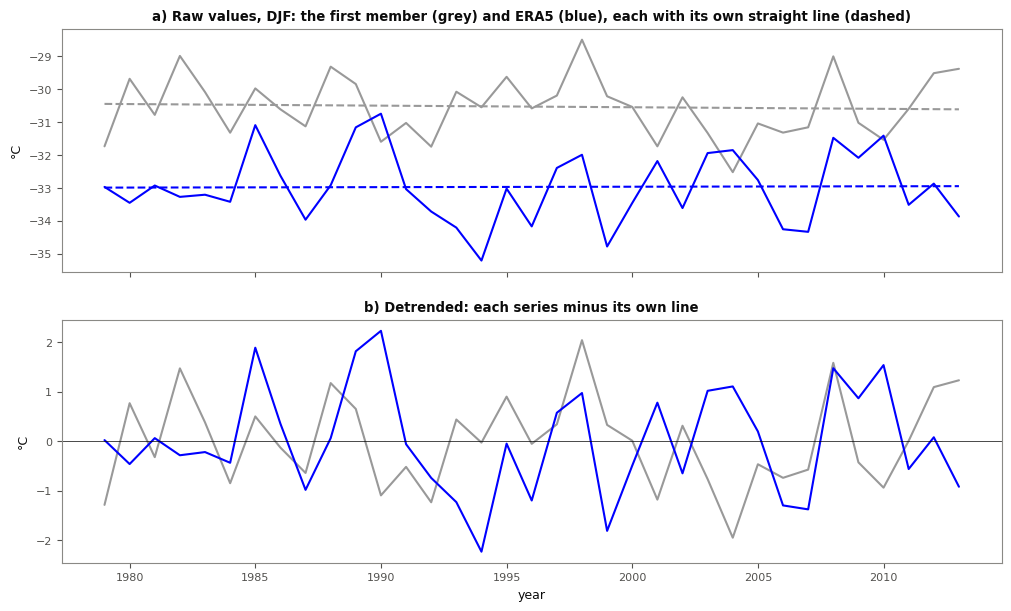

In [247]:
#(t): Detrending in the example: a) the first member (grey) and ERA5 (blue), each with its own straight line (dashed);
#(t): b) what is left of each once its line is taken away
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')
example_members_da.isel(member=0).plot(ax=ax1, color='0.6')
example_first_line_da.plot(ax=ax1, color='0.6', linestyle='--')
example_era5_da.plot(ax=ax1, color='blue')
example_era5_line_da.plot(ax=ax1, color='blue', linestyle='--')
ax1.set(title='a) Raw values, DJF: the first member (grey) and ERA5 (blue), each with its own straight line (dashed)',
        xlabel='', ylabel=VARIABLE.units)
example_members_detrended_da.isel(member=0).plot(ax=ax2, color='0.6')
example_era5_detrended_da.plot(ax=ax2, color='blue')
ax2.axhline(0, color='k', linewidth=0.5)
ax2.set(title='b) Detrended: each series minus its own line', ylabel=VARIABLE.units);

In [248]:
#(t): Every member at every grid point, each minus its own straight line
historical_detrended_tree = historical_tree.map_over_datasets(skip_empty(ev.detrend))

In [249]:
#(t): ... and ERA5
era5_detrended_da = ev.detrend(era5_obs_da)

## Moment Test

The first four moments of each series: the **mean** of the raw values, then the **standard deviation**, **skewness** and **excess kurtosis** of the detrended values. To work a moment out on other values, start its example and its every-grid-point cell from another series (`example_members_da` or `example_members_detrended_da`, `historical_tree` or `historical_detrended_tree`, and the matching ERA5).

### Mean (raw values)

Each series' average over the 35 years, in each season: (x₁₉₇₉ + x₁₉₈₀ + … + x₂₀₁₃) / 35. It is the climatology, so a model's mean-state bias shows here and in no other statistic. (The climatologies above are these means averaged over each model's members.)

In [250]:
#(t): Example: each member's mean, on (member)
example_mean_da = example_members_da.mean('year')

In [251]:
#(t): ... and ERA5's
example_era5_mean_da = example_era5_da.mean('year')

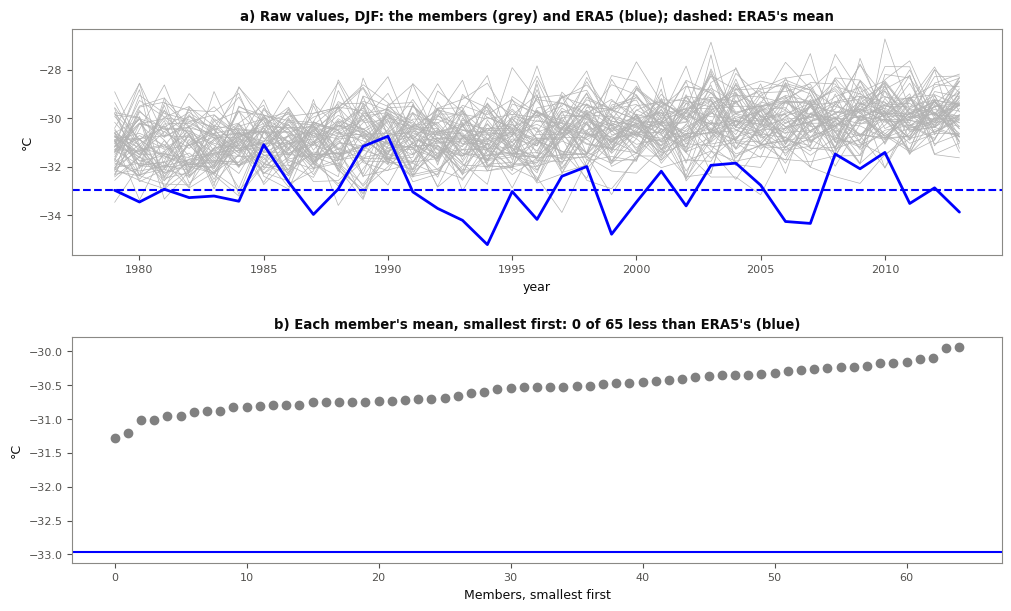

In [252]:
#(t): The mean in the example: a) the members (grey) and ERA5 (blue) through the years, ERA5's mean dashed; b) each
#(t): member's mean, smallest first, and ERA5's (blue)
n_less = int((example_mean_da < example_era5_mean_da).sum())
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), layout='constrained')
example_members_da.plot.line(ax=ax1, x='year', hue='member', add_legend=False, color='0.7', lw=0.5)
example_era5_da.plot(ax=ax1, color='blue', linewidth=2)
ax1.axhline(float(example_era5_mean_da), color='blue', linestyle='--')
ax1.set(title="a) Raw values, DJF: the members (grey) and ERA5 (blue); dashed: ERA5's mean", ylabel=VARIABLE.units)
ax2.scatter(np.arange(example_mean_da.sizes['member']), np.sort(example_mean_da.values), color='0.5')
ax2.axhline(float(example_era5_mean_da), color='blue')
ax2.set(title=f"b) Each member's mean, smallest first: {n_less} of {example_mean_da.sizes['member']} less than ERA5's (blue)",
        xlabel='Members, smallest first', ylabel=VARIABLE.units);

In [253]:
#(t): Every member's mean at every grid point, every model, on (member, season, lat, lon)
historical_mean_tree = historical_tree.mean('year')
historical_mean_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, season) float32 3MB dask.array<chunksize=(65, 4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (member: 63, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float32 3MB dask.array<chunksize=(63, 4, 144, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (member: 43, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float32 2MB dask.array<chunksize=(43, 4, 144, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (member: 55, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, season) float32 3MB dask.array<chunksize=(55, 4, 144, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (member: 50, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float32 2MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (member: 51, lat: 20, lon: 144, season: 4)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
              * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, lat, lon, season) float32 2MB dask.array<chunksize=(51, 4, 144, 4), meta=np.ndarray>

In [254]:
#(t): ERA5's, on (season, lat, lon)
era5_mean_da = era5_obs_da.mean('year')

In [255]:
#(t): Check: at the point in DJF the maps give the example. The same line makes both, here and in every section below;
#(t): the largest difference is rounding (about 0.00001 °C), from adding the same 35 numbers up in a different order
float(abs(historical_mean_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].sel(SAMPLE_LAT_LON).sel(season='DJF')
          - example_mean_da).max())

7.62939453125e-06

In [ ]:
%%time
#(t): Saved: every member's mean, as the variable mean of /<model>/historical in the one store
xr.DataTree.from_dict({node.path: node.to_dataset().rename({VARIABLE.name: 'mean'})
                       for node in historical_mean_tree.leaves}).to_zarr(statistics_path, mode='a')
statistics_path

In [ ]:
#(t): ... and ERA5's, as the variable mean of /ERA5
era5_mean_da.to_dataset(name='mean').to_zarr(statistics_path, group='ERA5', mode='a')
statistics_path

### Standard deviation (detrended)

How far a typical year is from the series' own straight line: the square root of the detrended values' squares added up and divided by 34 (the 35 years less one, `ddof=1`). The year-to-year noise.

In [258]:
#(t): Example: the standard deviation of each member's detrended values, on (member)
example_std_da = example_members_detrended_da.std('year', ddof=1)

In [259]:
#(t): ... and of ERA5's
example_era5_std_da = example_era5_detrended_da.std('year', ddof=1)

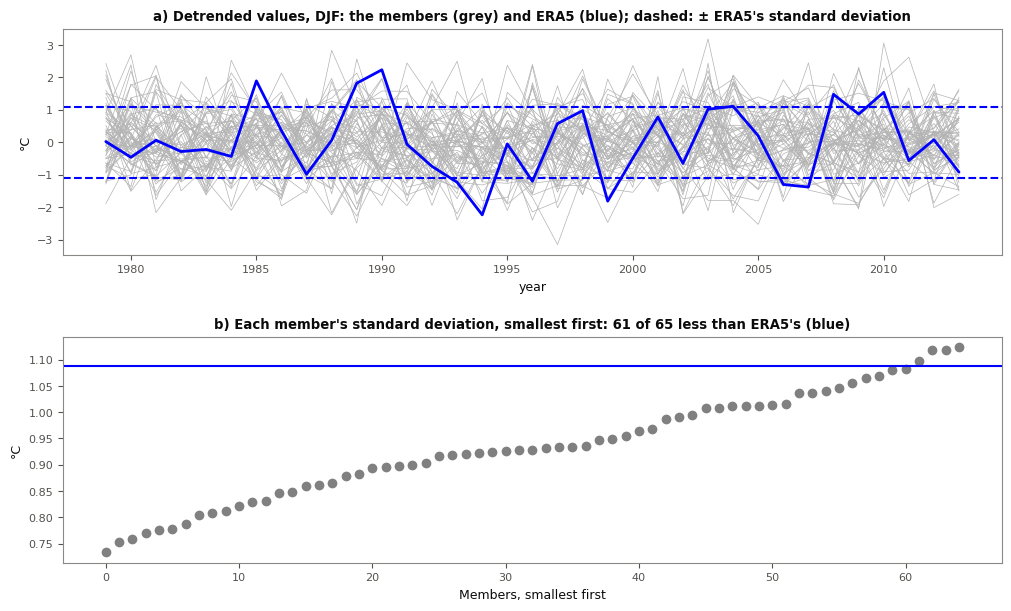

In [260]:
#(t): The standard deviation in the example: a) the members' detrended values (grey) and ERA5's (blue), with ERA5's
#(t): standard deviation either side of 0 (dashed); b) each member's standard deviation, smallest first, and ERA5's (blue)
n_less = int((example_std_da < example_era5_std_da).sum())
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), layout='constrained')
example_members_detrended_da.plot.line(ax=ax1, x='year', hue='member', add_legend=False, color='0.7', lw=0.5)
example_era5_detrended_da.plot(ax=ax1, color='blue', linewidth=2)
for sign in (-1, 1):
    ax1.axhline(sign * float(example_era5_std_da), color='blue', linestyle='--')
ax1.set(title="a) Detrended values, DJF: the members (grey) and ERA5 (blue); dashed: ± ERA5's standard deviation",
        ylabel=VARIABLE.units)
ax2.scatter(np.arange(example_std_da.sizes['member']), np.sort(example_std_da.values), color='0.5')
ax2.axhline(float(example_era5_std_da), color='blue')
ax2.set(title=f"b) Each member's standard deviation, smallest first: {n_less} of {example_std_da.sizes['member']} less "
              "than ERA5's (blue)", xlabel='Members, smallest first', ylabel=VARIABLE.units);

In [261]:
#(t): Every member's at every grid point, every model, on (member, season, lat, lon)
historical_std_tree = historical_detrended_tree.std('year', ddof=1)
historical_std_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(65, 4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (member: 63, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(63, 4, 144, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (member: 43, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 4MB dask.array<chunksize=(43, 4, 144, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (member: 55, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(55, 4, 144, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (member: 50, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (member: 51, lat: 20, lon: 144, season: 4)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
              * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(51, 4, 144, 4), meta=np.ndarray>

In [262]:
#(t): ERA5's
era5_std_da = era5_detrended_da.std('year', ddof=1)

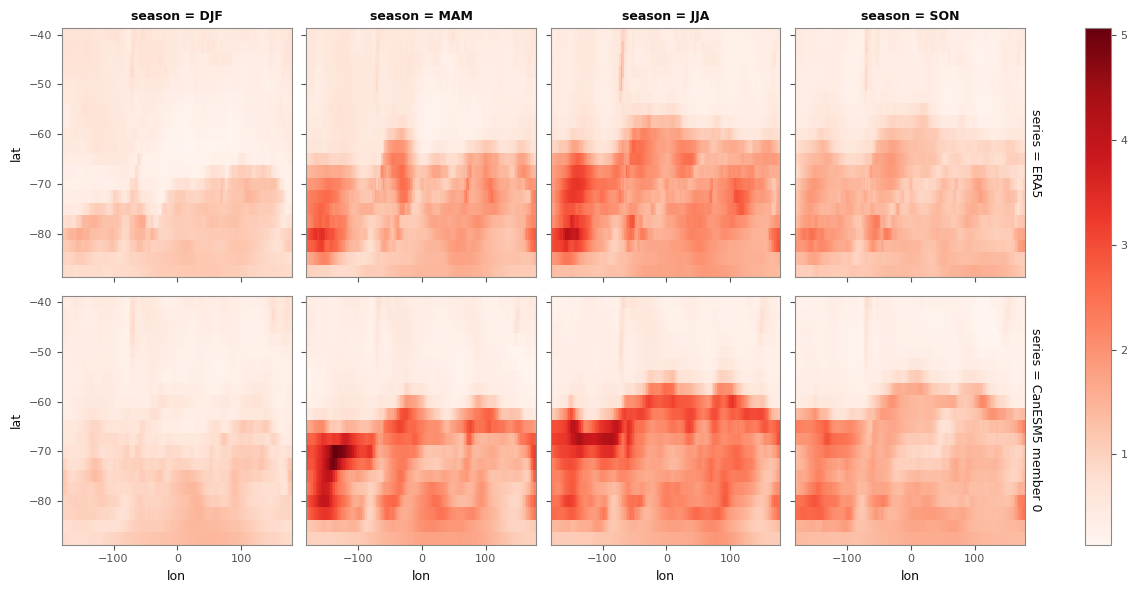

In [263]:
#(t): Quick look: ERA5's standard deviation (top) and EXAMPLE_MODEL's first member's (bottom) at every grid point, every season
first_member_std_da = historical_std_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].isel(member=0, drop=True)
quick_look_da = xr.concat([era5_std_da, first_member_std_da],
                          dim=xr.Variable('series', ['ERA5', f'{EXAMPLE_MODEL} member 0']))
quick_look_da.sel(season=SEASONS).plot(x='lon', y='lat', row='series', col='season', cmap='Reds');

In [ ]:
%%time
#(t): Saved: every member's standard deviation, as the variable std of /<model>/historical in the one store
xr.DataTree.from_dict({node.path: node.to_dataset().rename({VARIABLE.name: 'std'})
                       for node in historical_std_tree.leaves}).to_zarr(statistics_path, mode='a')
statistics_path

In [ ]:
#(t): ... and ERA5's, as the variable std of /ERA5
era5_std_da.to_dataset(name='std').to_zarr(statistics_path, group='ERA5', mode='a')
statistics_path

### Skewness (detrended)

Whether the warm side or the cold side of the series reaches further from its straight line (`ev.skewness`): the detrended values cubed and averaged, divided by their standard deviation cubed (both over the 35 years, not 34). Cubing keeps the sign and makes the years furthest from the line count most, so the skewness is greater than 0 when the warmest years reach further above the line than the coldest years reach below it, less than 0 the other way round, and 0 for a symmetric distribution.

In [266]:
#(t): Example: each member's skewness, on (member)
example_skewness_da = ev.skewness(example_members_detrended_da)

In [267]:
#(t): ... and ERA5's
example_era5_skewness_da = ev.skewness(example_era5_detrended_da)

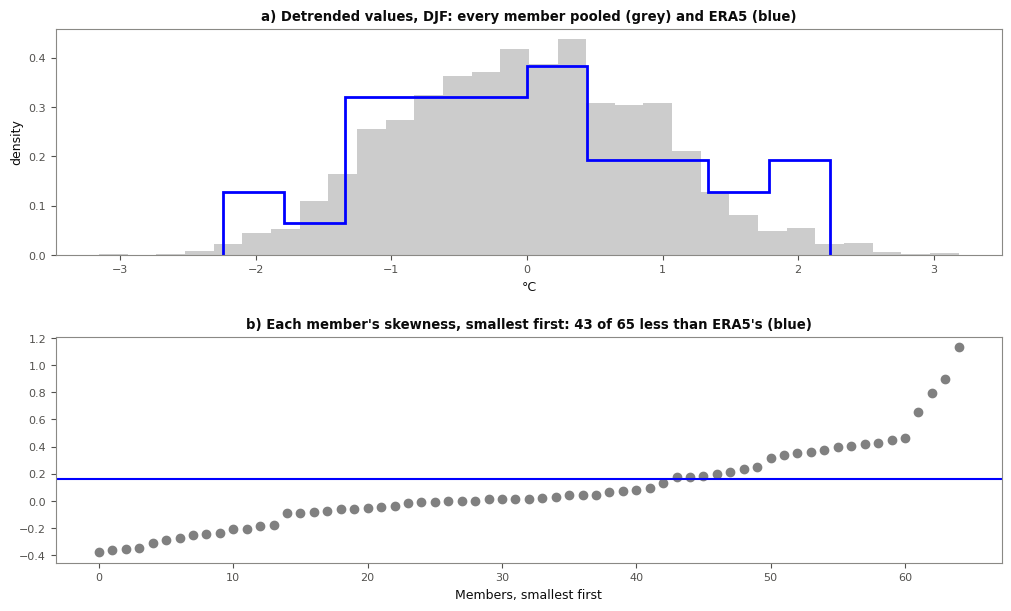

In [268]:
#(t): The skewness in the example: a) every member's detrended values pooled (grey) and ERA5's (blue), as histograms;
#(t): b) each member's skewness, smallest first, and ERA5's (blue)
n_less = int((example_skewness_da < example_era5_skewness_da).sum())
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), layout='constrained')
ax1.hist(example_members_detrended_da.values.ravel(), bins=30, density=True, color='0.8')
ax1.hist(example_era5_detrended_da.values, bins=10, density=True, histtype='step', color='blue', linewidth=2)
ax1.set(title='a) Detrended values, DJF: every member pooled (grey) and ERA5 (blue)', xlabel=VARIABLE.units,
        ylabel='density')
ax2.scatter(np.arange(example_skewness_da.sizes['member']), np.sort(example_skewness_da.values), color='0.5')
ax2.axhline(float(example_era5_skewness_da), color='blue')
ax2.set(title=f"b) Each member's skewness, smallest first: {n_less} of {example_skewness_da.sizes['member']} less "
              "than ERA5's (blue)", xlabel='Members, smallest first');

In [269]:
#(t): Every member's at every grid point, every model, on (member, season, lat, lon)
historical_skewness_tree = historical_detrended_tree.map_over_datasets(skip_empty(ev.skewness))
historical_skewness_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 65)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(65, 4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (lon: 144, lat: 20, member: 63, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(63, 4, 144, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (lat: 20, season: 4, lon: 144, member: 43)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 4MB dask.array<chunksize=(43, 4, 144, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 55)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(55, 4, 144, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 50)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (lon: 144, season: 4, lat: 20, member: 51)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
              * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(51, 4, 144, 4), meta=np.ndarray>

In [270]:
#(t): ERA5's
era5_skewness_da = ev.skewness(era5_detrended_da)

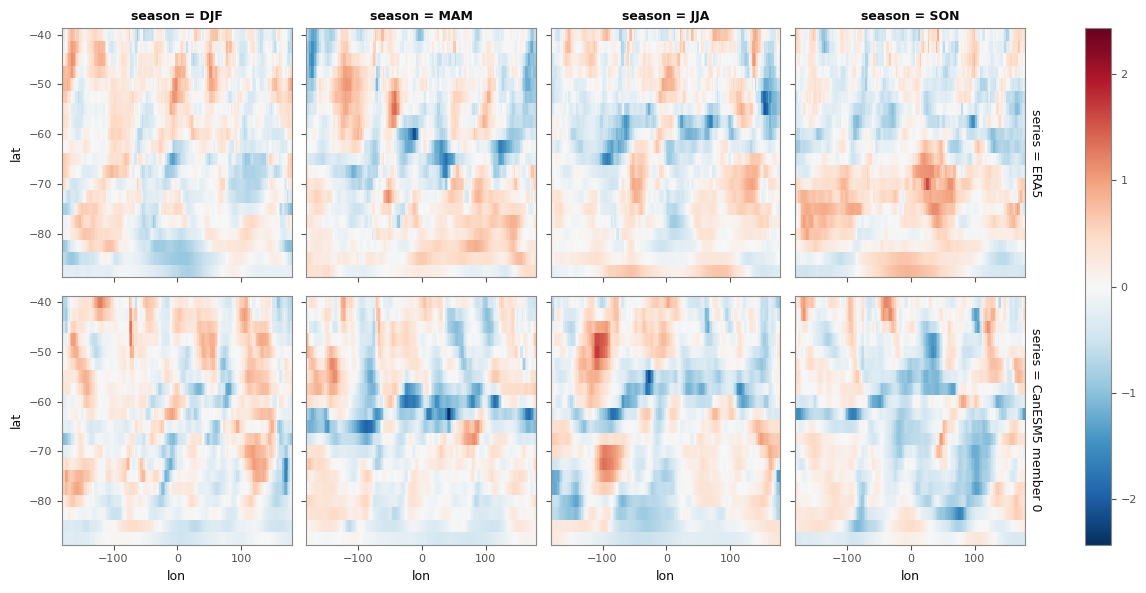

In [271]:
#(t): Quick look: ERA5's skewness (top) and EXAMPLE_MODEL's first member's (bottom) at every grid point, every season
first_member_skewness_da = historical_skewness_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].isel(member=0, drop=True)
quick_look_da = xr.concat([era5_skewness_da, first_member_skewness_da],
                          dim=xr.Variable('series', ['ERA5', f'{EXAMPLE_MODEL} member 0']))
quick_look_da.sel(season=SEASONS).plot(x='lon', y='lat', row='series', col='season', cmap='RdBu_r', center=0);

In [ ]:
%%time
#(t): Saved: every member's skewness, as the variable skewness of /<model>/historical in the one store
xr.DataTree.from_dict({node.path: node.to_dataset().rename({VARIABLE.name: 'skewness'})
                       for node in historical_skewness_tree.leaves}).to_zarr(statistics_path, mode='a')
statistics_path

In [ ]:
#(t): ... and ERA5's, as the variable skewness of /ERA5
era5_skewness_da.to_dataset(name='skewness').to_zarr(statistics_path, group='ERA5', mode='a')
statistics_path

### Excess kurtosis (detrended)

How heavy the tails are (`ev.excess_kurtosis`): the detrended values to the fourth power and averaged, divided by their standard deviation to the fourth, minus 3. A normal distribution gives 3 before the minus, so 0 is normal; greater than 0 means a few years sit much further from the line than the rest (heavy tails), less than 0 that the years are spread more evenly (light tails).

In [274]:
#(t): Example: each member's excess kurtosis, on (member)
example_kurtosis_da = ev.excess_kurtosis(example_members_detrended_da)

In [275]:
#(t): ... and ERA5's
example_era5_kurtosis_da = ev.excess_kurtosis(example_era5_detrended_da)

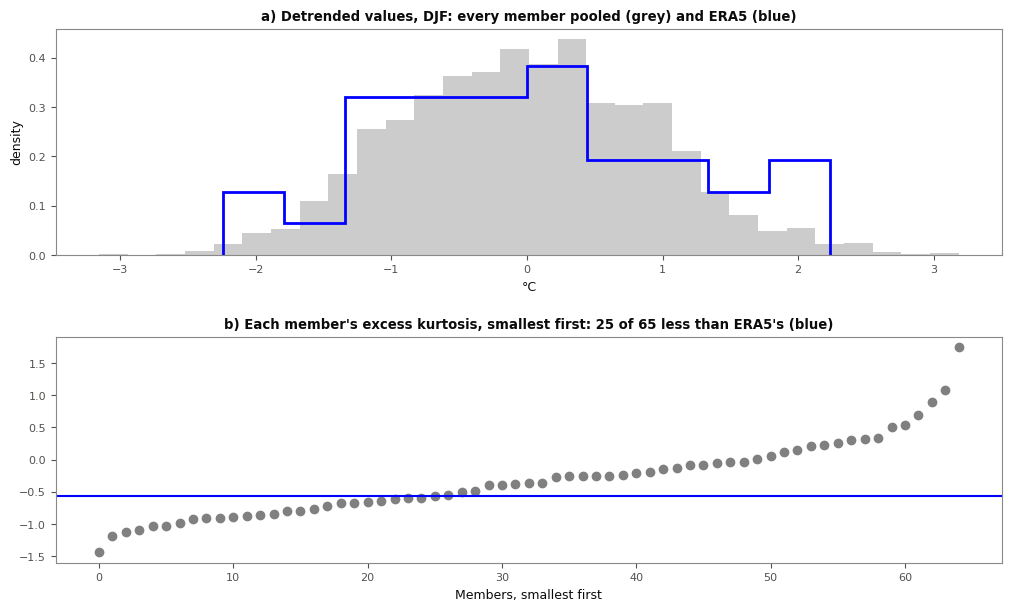

In [276]:
#(t): The excess kurtosis in the example: a) every member's detrended values pooled (grey) and ERA5's (blue), as histograms;
#(t): b) each member's excess kurtosis, smallest first, and ERA5's (blue)
n_less = int((example_kurtosis_da < example_era5_kurtosis_da).sum())
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), layout='constrained')
ax1.hist(example_members_detrended_da.values.ravel(), bins=30, density=True, color='0.8')
ax1.hist(example_era5_detrended_da.values, bins=10, density=True, histtype='step', color='blue', linewidth=2)
ax1.set(title='a) Detrended values, DJF: every member pooled (grey) and ERA5 (blue)', xlabel=VARIABLE.units,
        ylabel='density')
ax2.scatter(np.arange(example_kurtosis_da.sizes['member']), np.sort(example_kurtosis_da.values), color='0.5')
ax2.axhline(float(example_era5_kurtosis_da), color='blue')
ax2.set(title=f"b) Each member's excess kurtosis, smallest first: {n_less} of {example_kurtosis_da.sizes['member']} less "
              "than ERA5's (blue)", xlabel='Members, smallest first');

In [277]:
#(t): Every member's at every grid point, every model, on (member, season, lat, lon)
historical_kurtosis_tree = historical_detrended_tree.map_over_datasets(skip_empty(ev.excess_kurtosis))
historical_kurtosis_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 65)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(65, 4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (lon: 144, lat: 20, member: 63, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(63, 4, 144, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (lat: 20, season: 4, lon: 144, member: 43)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 4MB dask.array<chunksize=(43, 4, 144, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 55)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(55, 4, 144, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 50)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (lon: 144, season: 4, lat: 20, member: 51)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
              * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(51, 4, 144, 4), meta=np.ndarray>

In [278]:
#(t): ERA5's
era5_kurtosis_da = ev.excess_kurtosis(era5_detrended_da)

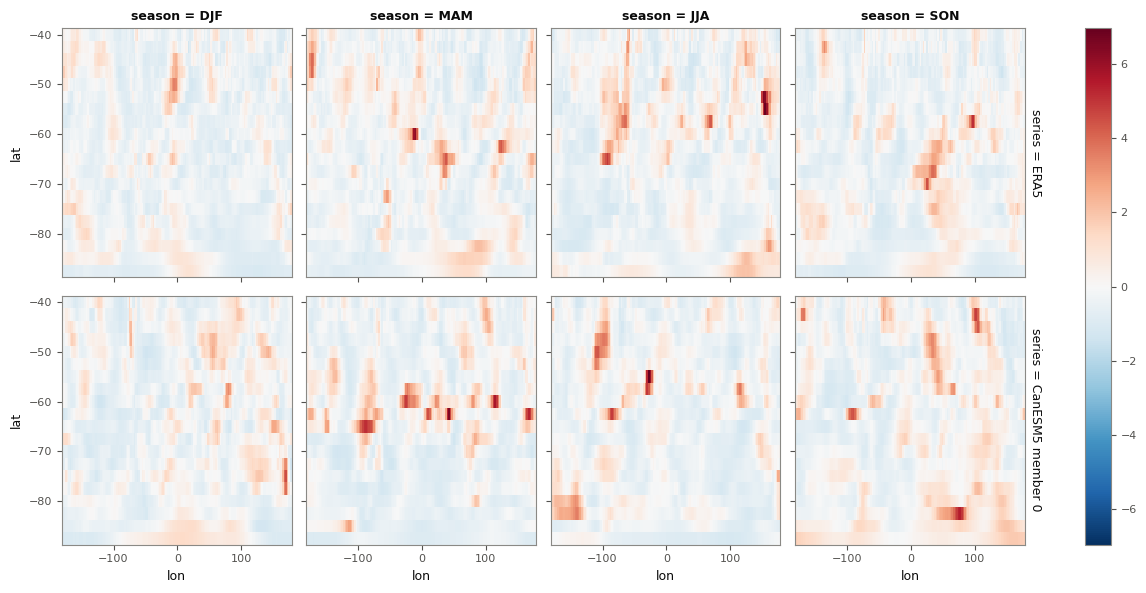

In [279]:
#(t): Quick look: ERA5's excess kurtosis (top) and EXAMPLE_MODEL's first member's (bottom) at every grid point, every season
first_member_kurtosis_da = historical_kurtosis_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].isel(member=0, drop=True)
quick_look_da = xr.concat([era5_kurtosis_da, first_member_kurtosis_da],
                          dim=xr.Variable('series', ['ERA5', f'{EXAMPLE_MODEL} member 0']))
quick_look_da.sel(season=SEASONS).plot(x='lon', y='lat', row='series', col='season', cmap='RdBu_r', center=0);

In [ ]:
%%time
#(t): Saved: every member's excess kurtosis, as the variable kurtosis of /<model>/historical in the one store
xr.DataTree.from_dict({node.path: node.to_dataset().rename({VARIABLE.name: 'kurtosis'})
                       for node in historical_kurtosis_tree.leaves}).to_zarr(statistics_path, mode='a')
statistics_path

In [ ]:
#(t): ... and ERA5's, as the variable kurtosis of /ERA5
era5_kurtosis_da.to_dataset(name='kurtosis').to_zarr(statistics_path, group='ERA5', mode='a')
statistics_path

## Other Statistics

Not moments, but worked out and saved in the same way: the **trend** of the raw values (the signal), and the **width** and the **lower and upper tails** of the detrended values (the noise, whose forced change notebook calc_02a analyses).

### Trend (raw values)

The slope of each series' least-squares straight line through the raw values, times 10 (`ev.trend`), in °C per decade: the warming or cooling over 1979–2013. It is the slope of the dashed lines that detrending took away.

In [282]:
#(t): Example: each member's trend, on (member)
example_trend_da = ev.trend(example_members_da)

In [283]:
#(t): ... and ERA5's
example_era5_trend_da = ev.trend(example_era5_da)

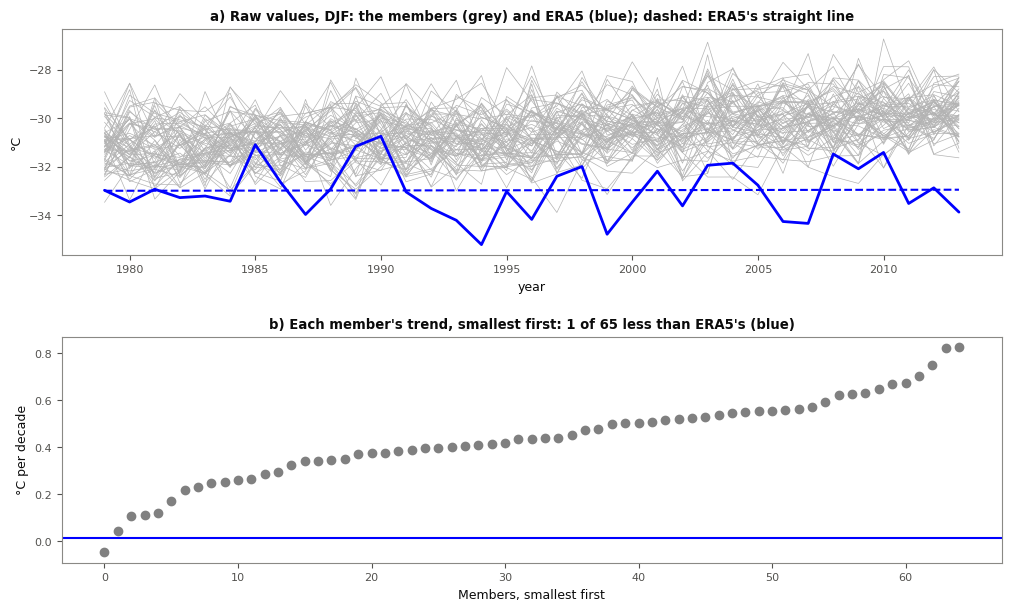

In [284]:
#(t): The trend in the example: a) the members (grey) and ERA5 (blue) through the years, with ERA5's straight line
#(t): (dashed); b) each member's trend, smallest first, and ERA5's (blue)
n_less = int((example_trend_da < example_era5_trend_da).sum())
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), layout='constrained')
example_members_da.plot.line(ax=ax1, x='year', hue='member', add_legend=False, color='0.7', lw=0.5)
example_era5_da.plot(ax=ax1, color='blue', linewidth=2)
example_era5_line_da.plot(ax=ax1, color='blue', linestyle='--')
ax1.set(title="a) Raw values, DJF: the members (grey) and ERA5 (blue); dashed: ERA5's straight line",
        ylabel=VARIABLE.units)
ax2.scatter(np.arange(example_trend_da.sizes['member']), np.sort(example_trend_da.values), color='0.5')
ax2.axhline(float(example_era5_trend_da), color='blue')
ax2.set(title=f"b) Each member's trend, smallest first: {n_less} of {example_trend_da.sizes['member']} less than "
              "ERA5's (blue)", xlabel='Members, smallest first', ylabel=f'{VARIABLE.units} per decade');

In [285]:
#(t): Every member's at every grid point, every model, on (member, season, lat, lon)
historical_trend_tree = historical_tree.map_over_datasets(skip_empty(ev.trend))
historical_trend_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(65, 4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (member: 63, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(63, 4, 144, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (member: 43, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 4MB dask.array<chunksize=(43, 4, 144, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (member: 55, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(55, 4, 144, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (member: 50, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (member: 51, lat: 20, lon: 144, season: 4)
            Coordinates:
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
              * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
              * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
            Data variables:
                tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(51, 4, 144, 4), meta=np.ndarray>

In [286]:
#(t): ERA5's
era5_trend_da = ev.trend(era5_obs_da)

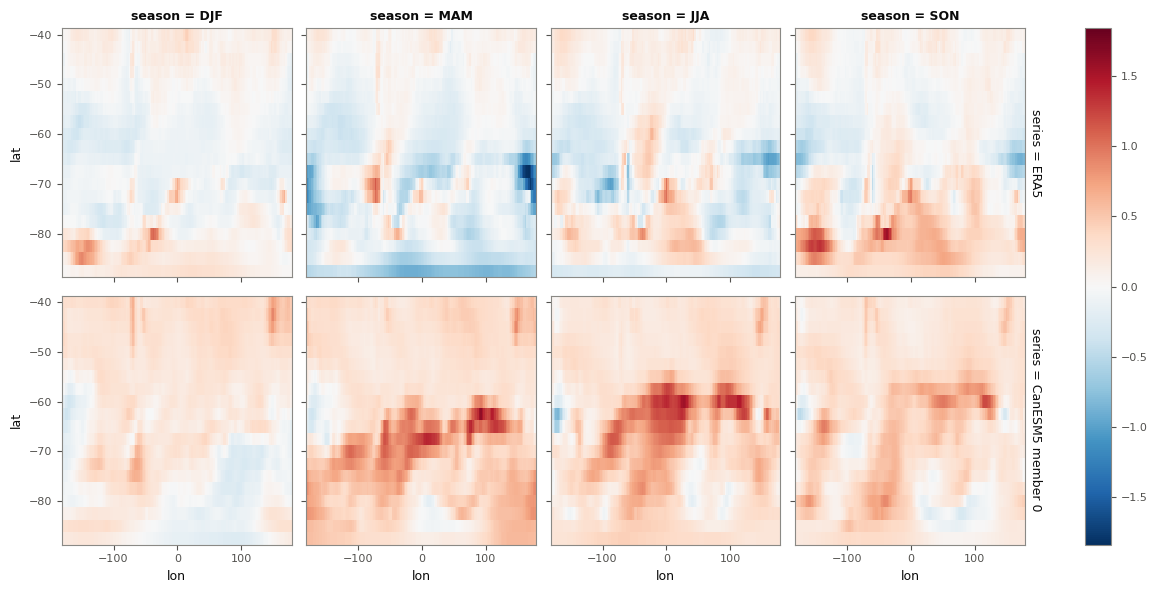

In [287]:
#(t): Quick look: ERA5's trend (top) and EXAMPLE_MODEL's first member's (bottom) at every grid point, every season
first_member_trend_da = historical_trend_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].isel(member=0, drop=True)
quick_look_da = xr.concat([era5_trend_da, first_member_trend_da],
                          dim=xr.Variable('series', ['ERA5', f'{EXAMPLE_MODEL} member 0']))
quick_look_da.sel(season=SEASONS).plot(x='lon', y='lat', row='series', col='season', cmap='RdBu_r', center=0);

In [ ]:
%%time
#(t): Saved: every member's trend, as the variable trend of /<model>/historical in the one store
xr.DataTree.from_dict({node.path: node.to_dataset().rename({VARIABLE.name: 'trend'})
                       for node in historical_trend_tree.leaves}).to_zarr(statistics_path, mode='a')
statistics_path

In [ ]:
#(t): ... and ERA5's, as the variable trend of /ERA5
era5_trend_da.to_dataset(name='trend').to_zarr(statistics_path, group='ERA5', mode='a')
statistics_path

### The 5th, 50th and 95th percentiles (detrended)

The width and both tails are differences between three percentiles of each series' detrended values. A percentile is read off the sorted years. With 35 years, the 5th percentile is (35 − 1) × 0.05 = 1.7 places up from the coldest year (which is place 0), so it is 70% of the way from the 2nd-coldest year to the 3rd-coldest. The 50th (the median) is place 17, the 18th-coldest year. The 95th is place 32.3, 30% of the way from the 3rd-warmest year to the 2nd-warmest. `nan_quantile` reads all three off every series at once.

In [290]:
#(t): Example: each member's 5th, 50th and 95th percentiles of its detrended values, on (member, quantile)
example_quantiles_da = nan_quantile(example_members_detrended_da, [0.05, 0.5, 0.95], 'year')

In [291]:
#(t): ... and ERA5's, on (quantile)
example_era5_quantiles_da = nan_quantile(example_era5_detrended_da, [0.05, 0.5, 0.95], 'year')

In [292]:
#(t): Check: ERA5's 5th percentile by hand, 70% of the way from its 2nd-coldest detrended year to its 3rd-coldest, and
#(t): nan_quantile's
era5_sorted_arr = np.sort(example_era5_detrended_da.values)
float(era5_sorted_arr[1] + 0.7 * (era5_sorted_arr[2] - era5_sorted_arr[1])), float(example_era5_quantiles_da.sel(quantile=0.05))

(-1.5110450987188089, -1.5110450987188087)

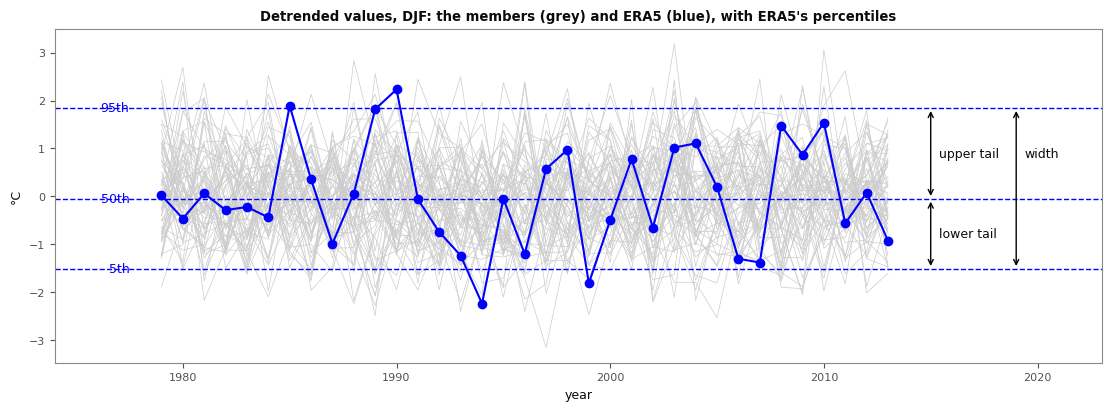

In [293]:
#(t): The percentiles in the example: the members' detrended values (grey) and ERA5's (blue), with ERA5's 5th, 50th and
#(t): 95th percentiles (dashed). The lower tail is the gap from the 5th up to the 50th, the upper tail from the 50th up
#(t): to the 95th, and the width from the 5th up to the 95th
era5_q05, era5_q50, era5_q95 = example_era5_quantiles_da.values
fig, ax = plt.subplots(figsize=(11, 4), layout='constrained')
example_members_detrended_da.plot.line(ax=ax, x='year', hue='member', add_legend=False, color='0.8', lw=0.5)
example_era5_detrended_da.plot(ax=ax, color='blue', marker='o', linewidth=1.5)
for value, name in [(era5_q05, '5th'), (era5_q50, '50th'), (era5_q95, '95th')]:
    ax.axhline(value, color='blue', linestyle='--', linewidth=1)
    ax.text(1977.5, value, name, color='blue', ha='right', va='center')
ax.annotate('', xy=(2015, era5_q50), xytext=(2015, era5_q05), arrowprops=dict(arrowstyle='<->'))
ax.text(2015.4, (era5_q05 + era5_q50) / 2, 'lower tail', va='center')
ax.annotate('', xy=(2015, era5_q95), xytext=(2015, era5_q50), arrowprops=dict(arrowstyle='<->'))
ax.text(2015.4, (era5_q50 + era5_q95) / 2, 'upper tail', va='center')
ax.annotate('', xy=(2019, era5_q95), xytext=(2019, era5_q05), arrowprops=dict(arrowstyle='<->'))
ax.text(2019.4, (era5_q50 + era5_q95) / 2, 'width', va='center')
ax.set(xlim=(1974, 2023), title="Detrended values, DJF: the members (grey) and ERA5 (blue), with ERA5's percentiles",
       ylabel=VARIABLE.units);

In [294]:
#(t): Every member's at every grid point, every model, on (member, season, lat, lon, quantile)
historical_quantiles_tree = historical_detrended_tree.map_over_datasets(skip_empty(nan_quantile), [0.05, 0.5, 0.95], 'year')

In [295]:
#(t): ERA5's, on (season, lat, lon, quantile)
era5_quantiles_da = nan_quantile(era5_detrended_da, [0.05, 0.5, 0.95], 'year')

### Width (detrended)

**Q95 − Q05**: the 95th percentile minus the 5th, the range the middle 90% of years fall in. It is the quantity whose forced change notebook calc_02a tests, and the two tails below added together.

In [296]:
#(t): Example: each member's width, Q95 - Q05, on (member)
example_width_da = example_quantiles_da.sel(quantile=0.95, drop=True) - example_quantiles_da.sel(quantile=0.05, drop=True)

In [297]:
#(t): ... and ERA5's
example_era5_width_da = (example_era5_quantiles_da.sel(quantile=0.95, drop=True)
                               - example_era5_quantiles_da.sel(quantile=0.05, drop=True))

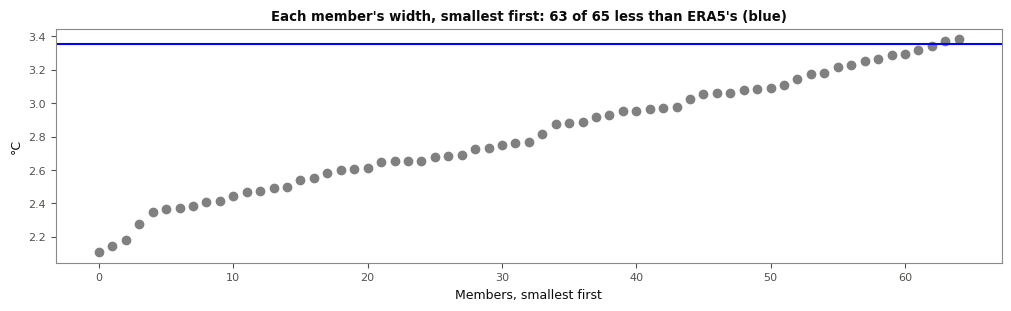

In [298]:
#(t): The width in the example: each member's, smallest first, and ERA5's (blue)
n_less = int((example_width_da < example_era5_width_da).sum())
fig, ax = plt.subplots(figsize=(10, 3), layout='constrained')
ax.scatter(np.arange(example_width_da.sizes['member']), np.sort(example_width_da.values), color='0.5')
ax.axhline(float(example_era5_width_da), color='blue')
ax.set(title=f"Each member's width, smallest first: {n_less} of {example_width_da.sizes['member']} less than ERA5's (blue)",
       xlabel='Members, smallest first', ylabel=VARIABLE.units);

In [299]:
#(t): Every member's at every grid point, every model, on (member, season, lat, lon)
historical_width_tree = (historical_quantiles_tree.sel(quantile=0.95, drop=True)
                               - historical_quantiles_tree.sel(quantile=0.05, drop=True))
historical_width_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 65)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(65, 4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (lon: 144, lat: 20, member: 63, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(63, 4, 144, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (lat: 20, season: 4, lon: 144, member: 43)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 4MB dask.array<chunksize=(43, 4, 144, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 55)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(55, 4, 144, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 50)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (lon: 144, season: 4, lat: 20, member: 51)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
              * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(51, 4, 144, 4), meta=np.ndarray>

In [300]:
#(t): ERA5's
era5_width_da = era5_quantiles_da.sel(quantile=0.95, drop=True) - era5_quantiles_da.sel(quantile=0.05, drop=True)

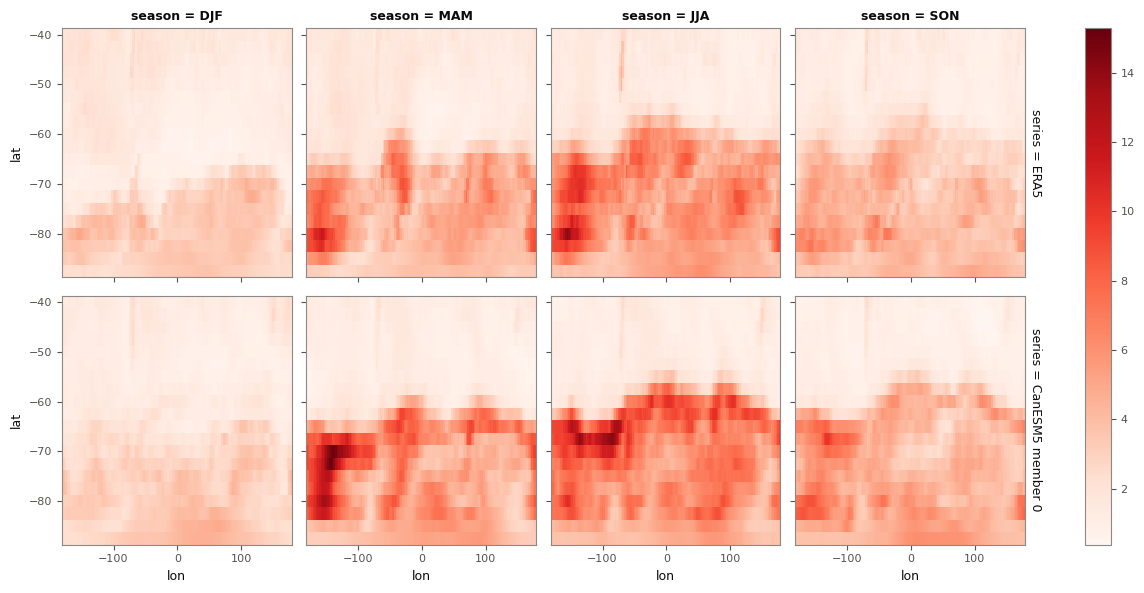

In [301]:
#(t): Quick look: ERA5's width (top) and EXAMPLE_MODEL's first member's (bottom) at every grid point, every season
first_member_width_da = historical_width_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].isel(member=0, drop=True)
quick_look_da = xr.concat([era5_width_da, first_member_width_da],
                          dim=xr.Variable('series', ['ERA5', f'{EXAMPLE_MODEL} member 0']))
quick_look_da.sel(season=SEASONS).plot(x='lon', y='lat', row='series', col='season', cmap='Reds');

In [ ]:
%%time
#(t): Saved: every member's width, as the variable width of /<model>/historical in the one store
xr.DataTree.from_dict({node.path: node.to_dataset().rename({VARIABLE.name: 'width'})
                       for node in historical_width_tree.leaves}).to_zarr(statistics_path, mode='a')
statistics_path

In [ ]:
#(t): ... and ERA5's, as the variable width of /ERA5
era5_width_da.to_dataset(name='width').to_zarr(statistics_path, group='ERA5', mode='a')
statistics_path

### Lower tail (detrended)

**Q50 − Q05**: the median minus the 5th percentile, how far a cold year (between the 2nd- and 3rd-coldest of the 35) reaches below a typical year. Too large in a model means its cold years are too cold for its typical years.

In [304]:
#(t): Example: each member's lower tail, Q50 - Q05, on (member)
example_lower_tail_da = example_quantiles_da.sel(quantile=0.5, drop=True) - example_quantiles_da.sel(quantile=0.05, drop=True)

In [305]:
#(t): ... and ERA5's
example_era5_lower_tail_da = (example_era5_quantiles_da.sel(quantile=0.5, drop=True)
                               - example_era5_quantiles_da.sel(quantile=0.05, drop=True))

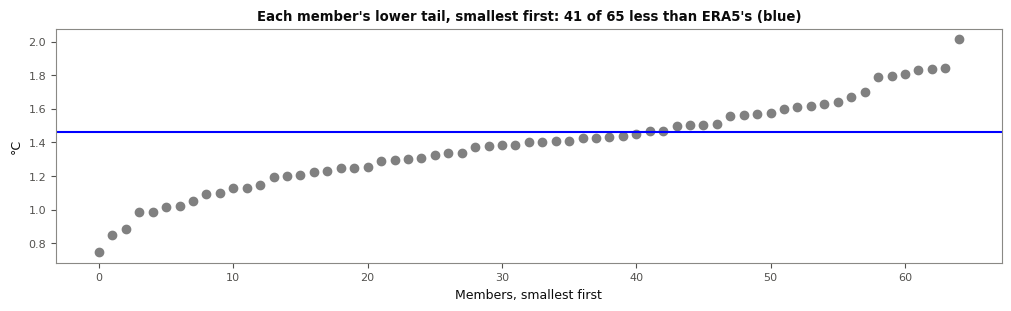

In [306]:
#(t): The lower tail in the example: each member's, smallest first, and ERA5's (blue)
n_less = int((example_lower_tail_da < example_era5_lower_tail_da).sum())
fig, ax = plt.subplots(figsize=(10, 3), layout='constrained')
ax.scatter(np.arange(example_lower_tail_da.sizes['member']), np.sort(example_lower_tail_da.values), color='0.5')
ax.axhline(float(example_era5_lower_tail_da), color='blue')
ax.set(title=f"Each member's lower tail, smallest first: {n_less} of {example_lower_tail_da.sizes['member']} less than ERA5's (blue)",
       xlabel='Members, smallest first', ylabel=VARIABLE.units);

In [307]:
#(t): Every member's at every grid point, every model, on (member, season, lat, lon)
historical_lower_tail_tree = (historical_quantiles_tree.sel(quantile=0.5, drop=True)
                               - historical_quantiles_tree.sel(quantile=0.05, drop=True))
historical_lower_tail_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 65)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(65, 4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (lon: 144, lat: 20, member: 63, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(63, 4, 144, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (lat: 20, season: 4, lon: 144, member: 43)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 4MB dask.array<chunksize=(43, 4, 144, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 55)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(55, 4, 144, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 50)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (lon: 144, season: 4, lat: 20, member: 51)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
              * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(51, 4, 144, 4), meta=np.ndarray>

In [308]:
#(t): ERA5's
era5_lower_tail_da = era5_quantiles_da.sel(quantile=0.5, drop=True) - era5_quantiles_da.sel(quantile=0.05, drop=True)

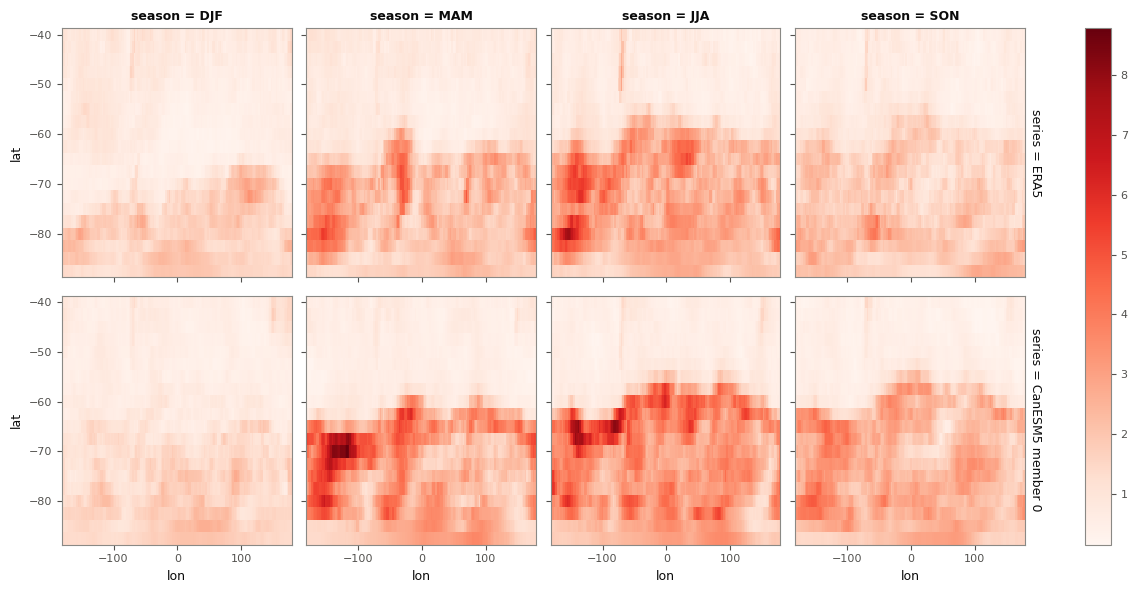

In [309]:
#(t): Quick look: ERA5's lower tail (top) and EXAMPLE_MODEL's first member's (bottom) at every grid point, every season
first_member_lower_tail_da = historical_lower_tail_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].isel(member=0, drop=True)
quick_look_da = xr.concat([era5_lower_tail_da, first_member_lower_tail_da],
                          dim=xr.Variable('series', ['ERA5', f'{EXAMPLE_MODEL} member 0']))
quick_look_da.sel(season=SEASONS).plot(x='lon', y='lat', row='series', col='season', cmap='Reds');

In [ ]:
%%time
#(t): Saved: every member's lower tail, as the variable lower_tail of /<model>/historical in the one store
xr.DataTree.from_dict({node.path: node.to_dataset().rename({VARIABLE.name: 'lower_tail'})
                       for node in historical_lower_tail_tree.leaves}).to_zarr(statistics_path, mode='a')
statistics_path

In [ ]:
#(t): ... and ERA5's, as the variable lower_tail of /ERA5
era5_lower_tail_da.to_dataset(name='lower_tail').to_zarr(statistics_path, group='ERA5', mode='a')
statistics_path

### Upper tail (detrended)

**Q95 − Q50**: the 95th percentile minus the median, how far a warm year (between the 3rd- and 2nd-warmest of the 35) reaches above a typical year.

In [312]:
#(t): Example: each member's upper tail, Q95 - Q50, on (member)
example_upper_tail_da = example_quantiles_da.sel(quantile=0.95, drop=True) - example_quantiles_da.sel(quantile=0.5, drop=True)

In [313]:
#(t): ... and ERA5's
example_era5_upper_tail_da = (example_era5_quantiles_da.sel(quantile=0.95, drop=True)
                               - example_era5_quantiles_da.sel(quantile=0.5, drop=True))

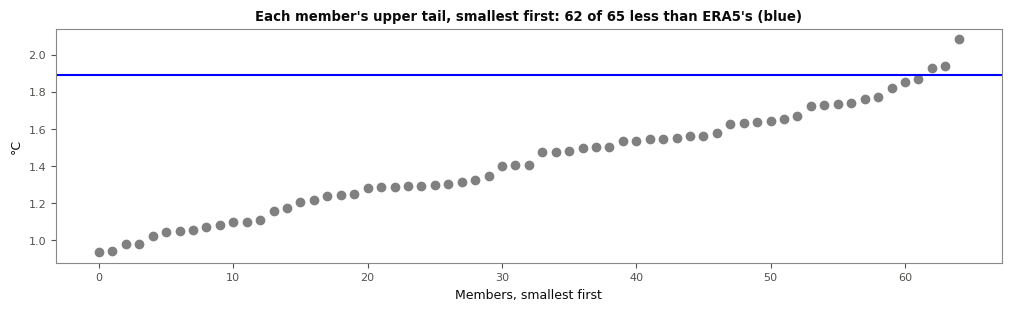

In [314]:
#(t): The upper tail in the example: each member's, smallest first, and ERA5's (blue)
n_less = int((example_upper_tail_da < example_era5_upper_tail_da).sum())
fig, ax = plt.subplots(figsize=(10, 3), layout='constrained')
ax.scatter(np.arange(example_upper_tail_da.sizes['member']), np.sort(example_upper_tail_da.values), color='0.5')
ax.axhline(float(example_era5_upper_tail_da), color='blue')
ax.set(title=f"Each member's upper tail, smallest first: {n_less} of {example_upper_tail_da.sizes['member']} less than ERA5's (blue)",
       xlabel='Members, smallest first', ylabel=VARIABLE.units);

In [315]:
#(t): Every member's at every grid point, every model, on (member, season, lat, lon)
historical_upper_tail_tree = (historical_quantiles_tree.sel(quantile=0.95, drop=True)
                               - historical_quantiles_tree.sel(quantile=0.5, drop=True))
historical_upper_tail_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 65)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(65, 4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:  (lon: 144, lat: 20, member: 63, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (member, lat, lon, season) float64 6MB dask.array<chunksize=(63, 4, 144, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/historical
│           Dimensions:  (lat: 20, season: 4, lon: 144, member: 43)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * member   (member) object 344B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 4MB dask.array<chunksize=(43, 4, 144, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 55)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(55, 4, 144, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 50)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/historical
            Dimensions:  (lon: 144, season: 4, lat: 20, member: 51)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
              * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
              * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
              * member   (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
            Data variables:
                tas      (member, lat, lon, season) float64 5MB dask.array<chunksize=(51, 4, 144, 4), meta=np.ndarray>

In [316]:
#(t): ERA5's
era5_upper_tail_da = era5_quantiles_da.sel(quantile=0.95, drop=True) - era5_quantiles_da.sel(quantile=0.5, drop=True)

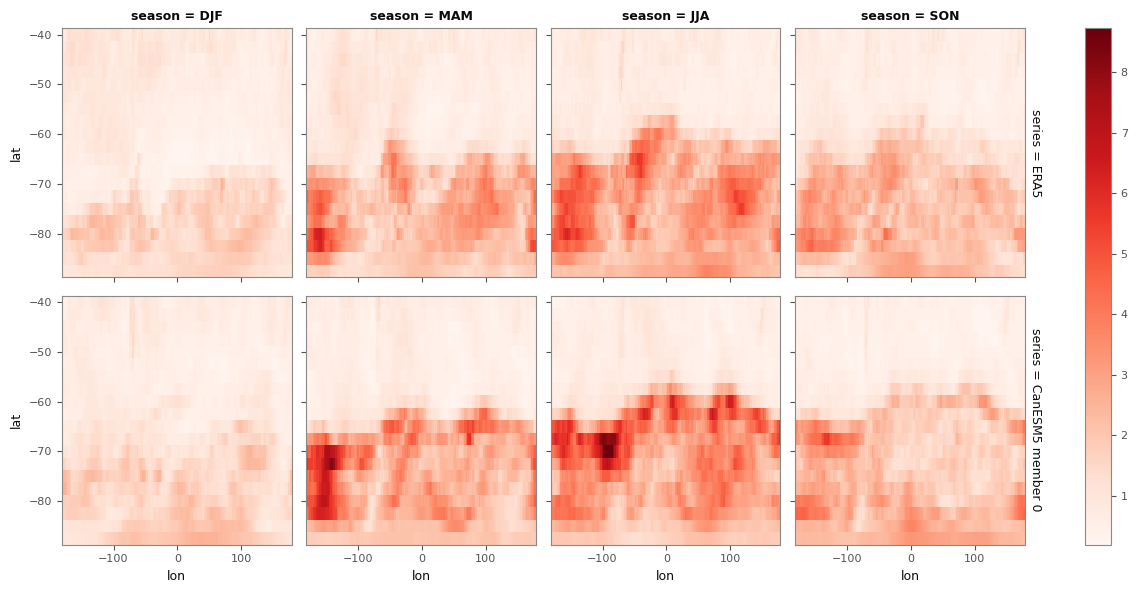

In [317]:
#(t): Quick look: ERA5's upper tail (top) and EXAMPLE_MODEL's first member's (bottom) at every grid point, every season
first_member_upper_tail_da = historical_upper_tail_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].isel(member=0, drop=True)
quick_look_da = xr.concat([era5_upper_tail_da, first_member_upper_tail_da],
                          dim=xr.Variable('series', ['ERA5', f'{EXAMPLE_MODEL} member 0']))
quick_look_da.sel(season=SEASONS).plot(x='lon', y='lat', row='series', col='season', cmap='Reds');

In [ ]:
%%time
#(t): Saved: every member's upper tail, as the variable upper_tail of /<model>/historical in the one store
xr.DataTree.from_dict({node.path: node.to_dataset().rename({VARIABLE.name: 'upper_tail'})
                       for node in historical_upper_tail_tree.leaves}).to_zarr(statistics_path, mode='a')
statistics_path

In [ ]:
#(t): ... and ERA5's, as the variable upper_tail of /ERA5
era5_upper_tail_da.to_dataset(name='upper_tail').to_zarr(statistics_path, group='ERA5', mode='a')
statistics_path

## Toy Ensembles with a Known Answer

Before trusting the tests on real data: synthetic ensembles where we *know* what is wrong (`ev.simulate_ensemble`: 50 members and a pseudo-ERA5, 1979–2013, four seasons, each series trend × decades + noise × N(0, 1)). Pseudo-ERA5 always has a trend of 0.3 per decade and noise 1; each scenario of `ev.SCENARIOS` changes one thing about the model. Here the mean, trend, standard deviation and width of every toy member and of pseudo-ERA5, worked out as above and saved as they are; plot_01b places pseudo-ERA5 among the members and draws them. Notebook calc_03b runs the rank-histogram tests and the plume on the same toy ensembles.

In [320]:
#(t): A toy ensemble and pseudo-ERA5 for each scenario, side by side on a scenario dim (all have 50 members)
demo_datasets = []
for settings in ev.SCENARIOS.values():
    demo_members_da, demo_era5_da = ev.simulate_ensemble(seed=3, **settings)
    demo_datasets.append(xr.Dataset({'members': demo_members_da, 'era5': demo_era5_da}))
demo_ds = xr.concat(demo_datasets, dim=xr.Variable('scenario', list(ev.SCENARIOS)))

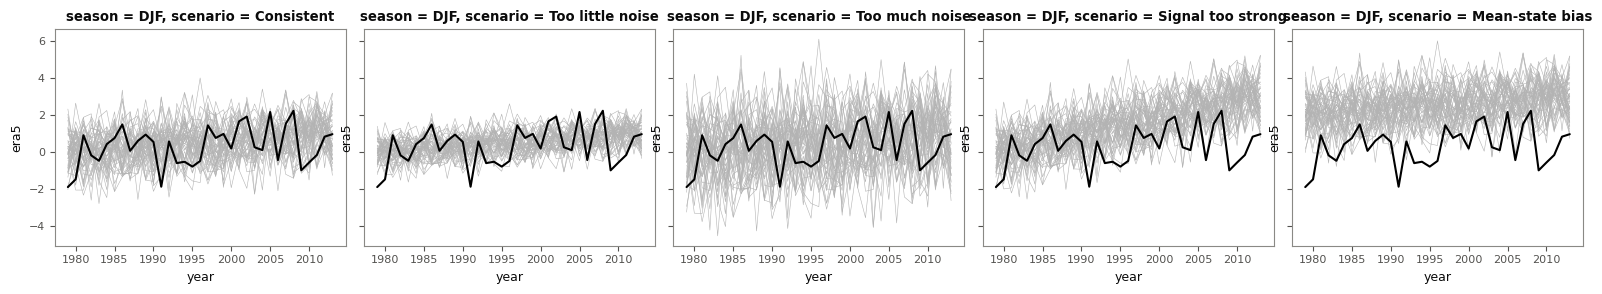

In [321]:
#(t): Quick look: each scenario's members (grey) and pseudo-ERA5 (black) in DJF
fg = demo_ds['members'].sel(season='DJF').plot.line(x='year', hue='member', col='scenario', add_legend=False,
                                                    color='0.7', lw=0.4)
for ax, scenario in zip(fg.axs.flat, demo_ds.scenario.values):
    demo_ds['era5'].sel(season='DJF', scenario=scenario).plot(ax=ax, color='k')

In [322]:
#(t): The detrended values
demo_detrended_ds = demo_ds.map(ev.detrend)

In [323]:
#(t): Each one's mean and trend of the raw values, and standard deviation and width (Q95 - Q05) of the detrended values,
#(t): for every member ('members') and pseudo-ERA5 ('era5')
demo_mean_ds = demo_ds.mean('year')
demo_trend_ds = demo_ds.map(ev.trend)
demo_std_ds = demo_detrended_ds.std('year', ddof=1)
demo_width_ds = nan_quantile(demo_detrended_ds, 0.95, 'year') - nan_quantile(demo_detrended_ds, 0.05, 'year')

In [324]:
#(t): The four along a statistic dim: the members on (statistic, scenario, member, season), pseudo-ERA5 on (statistic,
#(t): scenario, season)
demo_statistics_ds = xr.concat([demo_mean_ds, demo_trend_ds, demo_std_ds, demo_width_ds],
                               dim=xr.Variable('statistic', ['mean', 'trend', 'std', 'width']))
demo_statistics_ds

<xarray.Dataset> Size: 34kB
Dimensions:    (statistic: 4, scenario: 5, member: 50, season: 4)
Coordinates:
  * member     (member) int64 400B 0 1 2 3 4 5 6 7 8 ... 42 43 44 45 46 47 48 49
  * season     (season) <U3 48B 'DJF' 'MAM' 'JJA' 'SON'
  * scenario   (scenario) <U17 340B 'Consistent' ... 'Mean-state bias'
  * statistic  (statistic) <U5 80B 'mean' 'trend' 'std' 'width'
Data variables:
    members    (statistic, scenario, member, season) float64 32kB 0.4471 ... ...
    era5       (statistic, scenario, season) float64 640B 0.3109 0.6723 ... 3.26

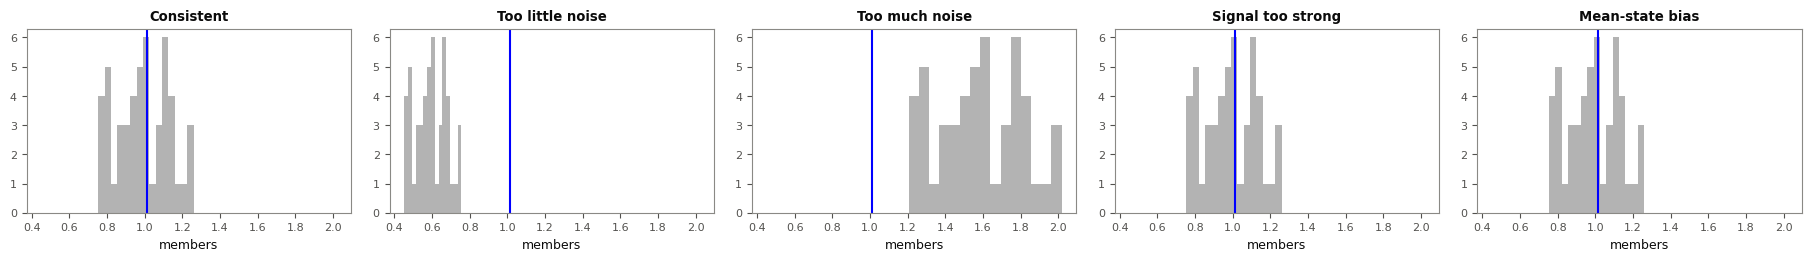

In [325]:
#(t): Quick look: every toy member's standard deviation (grey) and pseudo-ERA5's (blue) in DJF, one panel per scenario
fig, axes = plt.subplots(1, demo_statistics_ds.sizes['scenario'], figsize=(18, 2.5), sharex=True, layout='constrained')
for ax, scenario in zip(axes, demo_statistics_ds['scenario'].values):
    demo_statistics_ds['members'].sel(statistic='std', season='DJF', scenario=scenario).plot.hist(ax=ax, bins=15,
                                                                                                    color='0.7')
    ax.axvline(float(demo_statistics_ds['era5'].sel(statistic='std', season='DJF', scenario=scenario)), color='blue')
    ax.set_title(scenario)

In [326]:
#(t): Saved for plot_01b
demo_statistics_path = RESULTS_DIR / 'demo_statistics.zarr'
demo_statistics_ds.to_zarr(demo_statistics_path, mode='w')
demo_statistics_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/demo_statistics.zarr')

## Regional Evaluation

A regional mean averages away much of a grid point's noise, which is why the paper's verification is regional. Here ERA5's regional means (`era5_regional`), and the 1979–2013 trend in each region of every member of every experiment (`regional_trend`) and of ERA5 (`era5_regional_trend`), saved as they are. plot_06 places ERA5's regional trend among each experiment's members. The rank-histogram test of each region's mean is in notebook calc_03b (its section 9).

In [327]:
#(t): The regions (observed_change.REGIONS), as in part 2 (notebook calc_03c)
oc.REGIONS

{'Antarctica (90–65°S)': {'lat': slice(-90, -65, None)},
 'Antarctic Peninsula': {'lat': slice(-75, -62.5, None),
  'lon': slice(-75, -55, None)},
 'Southern Ocean (65–50°S)': {'lat': slice(-65, -50, None)}}

In [328]:
#(t): ERA5's regional means, on (region, year, season)
era5_regional_da = oc.regional_means(era5_seasonal_da).rename(VARIABLE.name)
era5_regional_da

<xarray.DataArray 'tas' (region: 3, year: 45, season: 4)> Size: 4kB
-11.84 -30.17 -23.17 -22.84 -12.22 -26.79 ... 0.5159 3.797 -0.1756 2.763 0.5638
Coordinates:
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year     (year) int64 360B 1979 1980 1981 1982 1983 ... 2020 2021 2022 2023
  * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...

In [329]:
#(t): Saved for notebook plot_06
era5_regional_path = RESULTS_DIR / 'era5_regional.zarr'
era5_regional_da.to_dataset(name=VARIABLE.name).to_zarr(era5_regional_path, mode='w')
era5_regional_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/era5_regional.zarr')

In [330]:
%%time
#(t): Every member's regional means over the ERA5 years, every model and experiment
regional_obs_tree = oc.regional_means(lesfmip_obs_tree).compute()

CPU times: user 12.8 s, sys: 20.7 s, total: 33.5 s
Wall time: 7.09 s


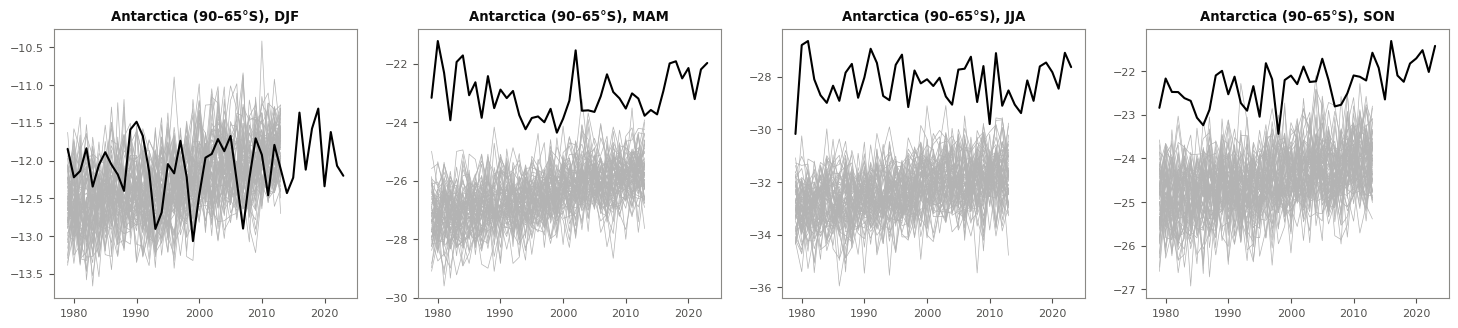

In [331]:
#(t): Quick look: ERA5 (black) among EXAMPLE_MODEL's historical members (grey) in the first region, every season
regional_ensemble_da = regional_obs_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].isel(region=0)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharex=True)
for ax, season in zip(axes, ev.SEASONS):
    ax.plot(regional_ensemble_da.year, regional_ensemble_da.sel(season=season).transpose('year', 'member'), color='0.7', lw=0.5)
    ax.plot(era5_regional_da.year, era5_regional_da.isel(region=0).sel(season=season), color='k')
    ax.set_title(f"{str(regional_ensemble_da.region.values)}, {season}")

In [332]:
%%time
#(t): Every member's regional trend (per decade), every model and experiment, on (member, region, season)
regional_trend_tree = regional_obs_tree.map_over_datasets(skip_empty(ev.trend))
regional_trend_tree

CPU times: user 244 ms, sys: 4.19 ms, total: 248 ms
Wall time: 249 ms


<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (region: 3, member: 50, season: 4)
│   │       Coordinates:
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (region, member, season) float64 5kB 0.2752 0.1596 ... 0.2399
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (region: 3, member: 30, season: 4)
│   │       Coordinates:
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (region, member, season) float64 3kB 0.02576 0.1781 ... -0.09727
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (region: 3, member: 50, season: 4)
│   │       Coordinates:
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (region, member, season) float64 5kB -0.02508 0.1277 ... 0.08584
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (region: 3, member: 10, season: 4)
│   │       Coordinates:
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (region, member, season) float64 960B -0.02519 0.4427 ... 0.07906
│   └── Group: /CanESM5/historical
│           Dimensions:  (region: 3, member: 65, season: 4)
│           Coordinates:
│             * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               tas      (region, member, season) float64 6kB 0.09218 0.4275 ... 0.2262
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (region: 3, member: 45, season: 4)
│   │       Coordinates:
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (region, member, season) float64 4kB 0.06509 0.2238 ... 0.1811
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (region: 3, member: 20, season: 4)
│   │       Coordinates:
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │         * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (region, member, season) float64 2kB 0.08957 0.03582 ... 0.0207
│   ├── Group: /GISS-E2-1-G/historical
│   │       Dimensions:  (region: 3, member: 63, season: 4)
│   │       Coordinates:
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │         * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (region, member, season) float64 6kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
│   ├── Group: /GISS-E2-1-G/hist-totalO3
│   │       Di

In [333]:
#(t): ERA5's regional trends over SATELLITE_YEAR_RANGE, on (region, season)
era5_regional_trend_da = ev.trend(era5_regional_da.sel(year=SATELLITE_YEAR_RANGE))
era5_regional_trend_da

<xarray.DataArray (region: 3, season: 4)> Size: 96B
-0.02101 -0.05292 -0.2236 0.1646 -0.05378 ... -0.08226 -0.07498 -0.1297 -0.06635
Coordinates:
  * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'

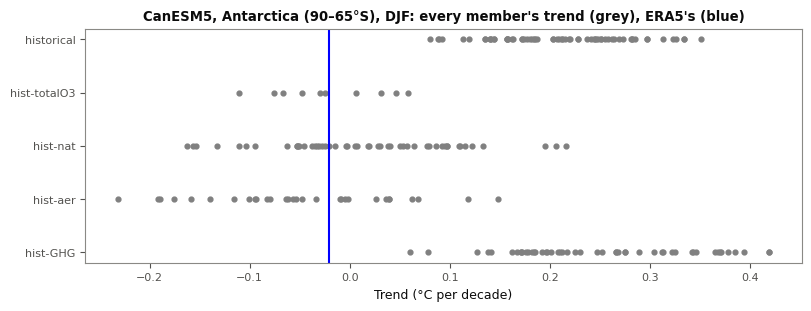

In [334]:
#(t): Quick look: EXAMPLE_MODEL's members' trends in each experiment (grey) and ERA5's (blue), in the first region, DJF
example_regional_trend_tree = regional_trend_tree[EXAMPLE_MODEL].isel(region=0).sel(season='DJF')
example_experiment_nodes = [node for node in example_regional_trend_tree.leaves if node.data_vars]
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
for row, node in enumerate(example_experiment_nodes):
    ax.scatter(node[VARIABLE.name].values, np.full(node.sizes['member'], row), color='0.5', s=12)
ax.axvline(float(era5_regional_trend_da.isel(region=0).sel(season='DJF')), color='blue')
ax.set(yticks=range(len(example_experiment_nodes)), yticklabels=[node.name for node in example_experiment_nodes],
       xlabel=f'Trend ({VARIABLE.units} per decade)',
       title=f"{EXAMPLE_MODEL}, {str(era5_regional_trend_da['region'].values[0])}, DJF: every member's trend (grey), ERA5's (blue)");

In [335]:
#(t): Saved for notebook plot_06: every member's regional trend
regional_trend_path = RESULTS_DIR / 'regional_trend.zarr'
regional_trend_tree.to_zarr(regional_trend_path, mode='w')
regional_trend_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_trend.zarr')

In [336]:
#(t): ... and ERA5's
era5_regional_trend_path = RESULTS_DIR / 'era5_regional_trend.zarr'
era5_regional_trend_da.to_dataset(name=VARIABLE.name).to_zarr(era5_regional_trend_path, mode='w')
era5_regional_trend_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/era5_regional_trend.zarr')